# Assignment 4

## Selected topic

**4. NLP: analyze and classify text → 4.3 Emotion Detection from Text (multiclass classification).**

- Dataset: [Emotion Detection from Text](https://www.kaggle.com/datasets/pashupatigupta/emotion-detection-from-text) (Kaggle, `tweet_emotions.csv`). It is a tweet-level corpus in which every tweet carries exactly one of 13 crowd-sourced emotion labels. Layout: `tweet_id`, `sentiment` (the emotion label, renamed to `emotion` below) and `content` (the tweet text, renamed to `text`).
- Task: given the text of a tweet, predict which of the 13 emotions it was labelled with.


## Exploratory Data Analysis (EDA)

Describe the dataset, its origin, structure, and variables. Calculate descriptive statistics (mean, median, standard deviation, quartiles). Investigate missing values, duplicates, and outliers. Analyze distributions and relationships between variables. Create at least 5 meaningful visualizations (employ dimensionality reduction where fit). Identify potential correlations and dependencies. Formulate at least 2 research questions or hypotheses. Explain data preprocessing decisions.

### 0. Setup, configuration and plotting style

Charts use one colour system throughout: a single blue for nominal categories that share one encoding, a one-hue blue ramp for magnitude, a blue↔red diverging scale (grey midpoint) for polarity, and at most three categorical hues (blue, orange, aqua; checked for colour-blind separation) where series must be told apart. Everything else is grey.

In [5]:

import os, re, glob, html, time, shutil, tempfile, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 1337
N_JOBS = -1
RUN_CV_TEST = True
CV_TEST_FOLDS = 5
TSNE_SAMPLE = 4000
rng = np.random.default_rng(SEED)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
GRAY, SURFACE, INK, INK2, GRID, AXIS = "#898781", "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, "#f0efec", RED])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
    "font.size": 9.5, "font.family": "sans-serif",
})

def grid(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def p_str(p):
    """'p = 0.082' or 'p < 1e-300': p-values underflow to exactly 0.0 for very strong effects, never print 'p = 0'."""
    return "p < 1e-300" if p == 0 else f"p = {p:.3g}"

print("Setup done. numpy", np.__version__, "| pandas", pd.__version__)


Setup done. numpy 2.5.4 | pandas 3.1.0


### 1. Dataset: origin, structure and variables

The *Emotion Detection from Text* dataset on Kaggle holds tweets that crowd workers labelled with **one** emotion out of 13 (`anger, boredom, empty, enthusiasm, fun, happiness, hate, love, neutral, relief, sadness, surprise, worry`). To my knowledge it derives from CrowdFlower's public "Emotion in Text" task (please confirm the provenance on the Kaggle page before citing it), and it is commonly reported to contain about 40 000 tweets; the cells below print the actual numbers.

| Column | Type | Meaning |
|---|---|---|
| `tweet_id` | integer | tweet identifier (not a feature) |
| `sentiment` → **`emotion`** | categorical (13 levels) | target label |
| `content` → **`text`** | string | tweet text: short, informal, with `@mentions`, `#hashtags`, URLs, emoticons, elongated words (*sooo*) and HTML entities |

This is a hard problem by construction: the labels are subjective (crowd workers disagree), several classes overlap semantically (e.g. *happiness*/*fun*/*enthusiasm*, *sadness*/*worry*/*empty*) and the text is very short.

In [6]:
def find_dataset():
    try:
        import kagglehub
        p = kagglehub.dataset_download("pashupatigupta/emotion-detection-from-text")
        hits = glob.glob(os.path.join(p, "**", "*.csv"), recursive=True)
        if hits:
            return hits[0]
    except Exception as e:
        print("kagglehub fallback failed:", type(e).__name__)
    raise FileNotFoundError("tweet_emotions.csv not found")

DATA_PATH = find_dataset()
raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
need = {"tweet_id", "sentiment", "content"}
assert need <= set(raw.columns), f"Unexpected schema. Expected {need}, got {list(raw.columns)}"
df = raw.rename(columns={"sentiment": "emotion", "content": "text"})[["tweet_id", "emotion", "text"]].copy()

print("shape:", df.shape, "| memory: %.1f MB" % (df.memory_usage(deep=True).sum() / 1e6))
display(df.dtypes.to_frame("dtype").T)
display(df.head(8))
print("distinct tweet_id:", df.tweet_id.nunique(), "| distinct emotions:", df.emotion.nunique())

Loaded: C:\Users\bodia\.cache\kagglehub\datasets\pashupatigupta\emotion-detection-from-text\versions\1\tweet_emotions.csv
shape: (40000, 3) | memory: 4.1 MB


,tweet_id,emotion,text
dtype,int64,str,str


,tweet_id,emotion,text
0,1956967341,empty,@tiffanylue i know i was listenin to bad habi...
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin o...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,@dannycastillo We want to trade with someone w...
5,1956968477,worry,Re-pinging @ghostridah14: why didn't you go to...
6,1956968487,sadness,"I should be sleep, but im not! thinking about ..."
7,1956968636,worry,Hmmm. http://www.djhero.com/ is down


distinct tweet_id: 40000 | distinct emotions: 13


### 2. Data quality: missing values, duplicates, label conflicts

Duplicates matter more than usual here. If the same tweet (or a retweet that differs only in the `@mention`) lands in both the training and the test split, test scores are inflated; if the same text carries two different labels, the "correct" answer is undefined. Both are checked on the *normalised* text, so `"@bob so happy!!!"` and `"@amy so happy!!"` count as the same tweet.

In [7]:
print("missing values per column:\n" + df.isna().sum().to_string())
df = df.dropna(subset=["text", "emotion"]).copy()
print("\nempty / whitespace-only texts:", int((df.text.str.strip() == "").sum()))
print("fully duplicated rows (all columns):", int(df.duplicated().sum()))
print("duplicated tweet_id:", int(df.tweet_id.duplicated().sum()))
print("duplicated raw texts:", int(df.text.duplicated().sum()))

missing values per column:
tweet_id    0
emotion     0
text        0

empty / whitespace-only texts: 0
fully duplicated rows (all columns): 0
duplicated tweet_id: 0
duplicated raw texts: 173


**Text normalisation** (reused later *inside* the model pipelines, so train and test are always treated identically):

| Step | Why |
|---|---|
| decode HTML entities (`&quot;`, `&amp;`, `&lt;3` → `<3`) | the raw file contains escaped characters; `<3` is a strong *love* cue |
| lower-case | case carries little lexical information (capital-letter ratio is kept as a separate numeric feature) |
| URLs → `urltoken`, `@mentions` → `usertoken` | the *presence* of a link/mention may matter, the particular one does not; also lets retweets collapse into one |
| `#hashtag` → `hashtag` word | the hashtag text is often the emotion word itself |
| squash letter/`!`/`?` repeats to two (`sooooo` → `soo`) | keeps the emphasis signal, removes vocabulary explosion |
| **keep** stop-words, negations, `!`, `?` and emoticons as tokens | *not*, *no*, *!!* and `:(` are exactly what separates emotions; an ablation in the ML part checks this empirically |

In [ ]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
REPEAT_RE = re.compile(r"([a-z!?])\1{2,}")
TOKEN_PATTERN = r"(?u)\b\w\w+\b|[!?]|[:;=]-?[()dpo/]|<3"

def clean_text(t):
    t = html.unescape(str(t)).lower()
    t = URL_RE.sub(" urltoken ", t)
    t = MENTION_RE.sub(" usertoken ", t)
    t = HASHTAG_RE.sub(r" \1 ", t)
    t = REPEAT_RE.sub(r"\1\1", t)
    return t

df["text_norm"] = df["text"].map(clean_text).str.split().str.join(" ")

n_raw = len(df)
n_empty = int((df.text_norm == "").sum())
by_text = df.groupby("text_norm")["emotion"].nunique()
conflict_keys = set(by_text[by_text > 1].index)
is_conflict = df.text_norm.isin(conflict_keys)
n_conflict_rows = int(is_conflict.sum())

df_clean = (df[(df.text_norm != "") & ~is_conflict]
            .drop_duplicates("text_norm")
            .reset_index(drop=True))

print(f"rows before cleaning                      : {n_raw:,}")
print(f"empty after normalisation (dropped)       : {n_empty:,}")
print(f"texts with conflicting labels (all copies dropped): {len(conflict_keys):,} texts / {n_conflict_rows:,} rows")
print(f"near-duplicate copies removed (kept first): {n_raw - n_empty - n_conflict_rows - len(df_clean):,}")
print(f"rows after cleaning                       : {len(df_clean):,}  ({len(df_clean)/n_raw:.1%} of original)")

rows before cleaning                      : 40,000
empty after normalisation (dropped)       : 0
texts with conflicting labels (all copies dropped): 159 texts / 719 rows
near-duplicate copies removed (kept first): 79
rows after cleaning                       : 39,202  (98.0% of original)


### 3. Descriptive statistics

Text is not numeric, so alongside the label distribution we derive nine simple numeric descriptors per tweet (length, punctuation, hashtags, mentions, URLs, share of capital letters, elongated words). They are used for the descriptive statistics and the correlation analysis, and later optionally fed to the models.

In [9]:
META_COLS = ["n_chars", "n_words", "n_exclaim", "n_question", "n_hashtags", "n_mentions", "n_urls", "upper_ratio", "elongated"]

def meta_features(s):
    """Numeric descriptors of the RAW tweet text (a pandas Series of str)."""
    f = pd.DataFrame(index=s.index)
    f["n_chars"] = s.str.len()
    f["n_words"] = s.str.split().str.len()
    f["n_exclaim"] = s.str.count("!")
    f["n_question"] = s.str.count(r"\?")
    f["n_hashtags"] = s.str.count(r"#\w+")
    f["n_mentions"] = s.str.count(r"@\w+")
    f["n_urls"] = s.str.count(r"https?://\S+|www\.\S+")
    f["upper_ratio"] = s.apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t)))
    f["elongated"] = s.str.count(r"(\w)\1{2,}")
    return f[META_COLS]

meta_c = meta_features(df_clean["text"])

desc = (meta_c.describe().T[["mean", "50%", "std", "min", "25%", "75%", "max"]]
        .rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"}))
desc["skew"] = meta_c.skew()
print("Descriptive statistics of the numeric descriptors (cleaned data):")
display(desc.round(3))

cls = df_clean.emotion.value_counts()
cls_tbl = pd.DataFrame({"count": cls, "share_%": (cls / len(df_clean) * 100).round(2)})
print("\nLabel distribution:")
display(cls_tbl.T)
print(f"imbalance ratio (largest / smallest class): {cls.max() / cls.min():.1f}")

by_class = meta_c.groupby(df_clean["emotion"].values)["n_words"].agg(["mean", "median", "std"]).round(2)
print("\nWords per tweet by emotion:")
display(by_class.loc[cls.index].T)

Descriptive statistics of the numeric descriptors (cleaned data):


,mean,median,std,min,Q1,Q3,max,skew
n_chars,74.139,69.000,36.209,6.0,44.000,104.000,167.0,0.257
n_words,13.370,12.000,6.909,1.0,8.000,19.000,34.0,0.373
n_exclaim,0.554,0.000,1.343,0.0,0.000,1.000,76.0,11.894
n_question,0.170,0.000,1.231,0.0,0.000,0.000,98.0,42.623
n_hashtags,0.023,0.000,0.185,0.0,0.000,0.000,9.0,13.682
n_mentions,0.497,0.000,0.571,0.0,0.000,1.000,10.0,1.308
n_urls,0.047,0.000,0.216,0.0,0.000,0.000,4.0,4.651
upper_ratio,0.062,0.041,0.097,0.0,0.012,0.076,1.0,5.580
elongated,0.109,0.000,0.385,0.0,0.000,0.000,9.0,4.909



Label distribution:


emotion,neutral,worry,sadness,happiness,love,surprise,fun,relief,hate,empty,enthusiasm,boredom,anger
count,8386.00,8348.00,5110.00,5092.00,3705.00,2157.0,1765.0,1498.00,1315.00,786.0,751.00,179.00,110.00
share_%,21.39,21.29,13.04,12.99,9.45,5.5,4.5,3.82,3.35,2.0,1.92,0.46,0.28


imbalance ratio (largest / smallest class): 76.2

Words per tweet by emotion:


,neutral,worry,sadness,happiness,love,surprise,fun,relief,hate,empty,enthusiasm,boredom,anger
mean,11.56,14.22,13.98,13.55,13.46,13.60,14.41,14.01,14.41,11.88,13.46,13.60,14.10
median,10.00,14.00,13.00,13.00,12.00,13.00,14.00,13.00,14.00,11.00,12.00,13.00,14.00
std,6.86,6.88,6.91,6.72,6.72,6.83,6.58,6.80,7.05,6.83,6.98,6.84,6.84


### 4. Outliers

For the two length variables the usual 1.5 × IQR fences are applied. The other descriptors are zero-inflated counts (most tweets have no URL, most have no hashtag), so IQR fences are meaningless for them (the IQR is 0 and every non-zero value would be an "outlier"); for those we report how often they occur and their maximum. **Decision: nothing is removed.** Long tweets and heavy punctuation are genuine text, not measurement errors, and a TF-IDF model is not sensitive to a few long documents (rows are L2-normalised).

In [10]:
rows = []
for c in ["n_chars", "n_words"]:
    s = meta_c[c]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append(dict(feature=c, lower_fence=lo, upper_fence=hi, n_outliers=int(((s < lo) | (s > hi)).sum()),
                     pct_outliers=round(float(((s < lo) | (s > hi)).mean() * 100), 2)))
display(pd.DataFrame(rows).set_index("feature"))

zero_inf = pd.DataFrame({"share_nonzero_%": (meta_c[["n_exclaim", "n_question", "n_hashtags", "n_mentions", "n_urls", "elongated"]] > 0).mean() * 100,
                         "max": meta_c[["n_exclaim", "n_question", "n_hashtags", "n_mentions", "n_urls", "elongated"]].max()}).round(2)
display(zero_inf.T)

,lower_fence,upper_fence,n_outliers,pct_outliers
feature,,,,
n_chars,-46.0,194.0,0,0.0
n_words,-8.5,35.5,0,0.0


,n_exclaim,n_question,n_hashtags,n_mentions,n_urls,elongated
share_nonzero_%,29.37,10.84,2.0,47.09,4.61,9.01
max,76.00,98.00,9.0,10.00,4.00,9.00


### 5. Visualisations

Eight figures: label balance, length distributions, behaviour of the numeric descriptors, discriminative vocabulary per emotion, similarity between emotions, and two dimensionality-reduction views (TruncatedSVD/LSA and t-SNE).

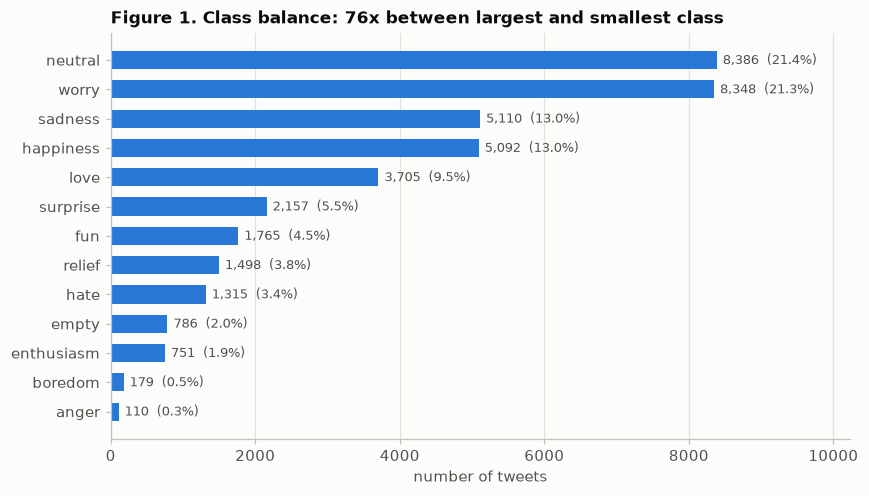

In [11]:
order = cls.sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(order, cls[order].values, color=BLUE, height=0.62)
for i, e in enumerate(order):
    ax.text(cls[e] + cls.max() * 0.01, i, f"{cls[e]:,}  ({cls[e] / len(df_clean):.1%})", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, cls.max() * 1.22)
ax.set_xlabel("number of tweets")
ax.set_title(f"Figure 1. Class balance: {cls.max() / cls.min():.0f}x between largest and smallest class")
grid(ax, "x")
plt.tight_layout(); plt.show()

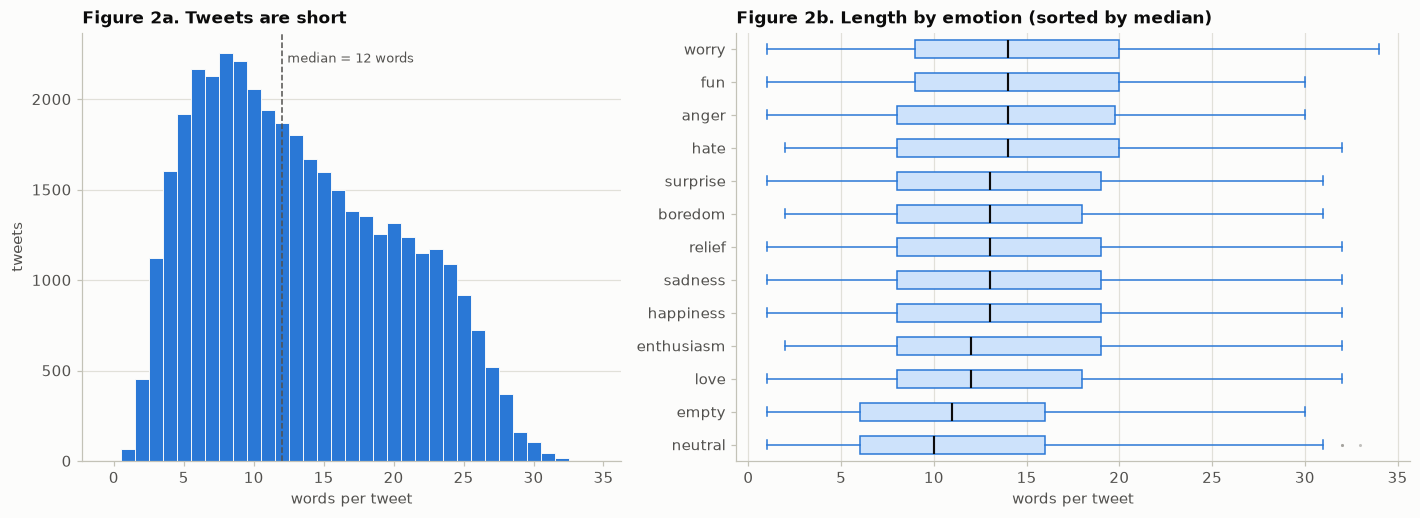

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax1.hist(meta_c["n_words"], bins=np.arange(0, meta_c["n_words"].max() + 2) - 0.5, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax1.axvline(meta_c["n_words"].median(), color=INK2, linestyle="--", linewidth=1)
ax1.text(meta_c["n_words"].median() + 0.4, ax1.get_ylim()[1] * 0.93, f"median = {meta_c['n_words'].median():.0f} words", color=INK2, fontsize=8.5)
ax1.set_xlabel("words per tweet"); ax1.set_ylabel("tweets")
ax1.set_title("Figure 2a. Tweets are short")
grid(ax1, "y")

med = meta_c.groupby(df_clean["emotion"].values)["n_words"].median().sort_values()
data = [meta_c.loc[(df_clean["emotion"] == e).values, "n_words"].values for e in med.index]
box_style = dict(patch_artist=True, widths=0.55, showfliers=True,
                 flierprops=dict(marker="o", markersize=2, markerfacecolor=GRAY, markeredgecolor="none", alpha=0.5),
                 medianprops=dict(color=INK, linewidth=1.4), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                 boxprops=dict(color=BLUE))
try:
    bp = ax2.boxplot(data, orientation="horizontal", **box_style)
except TypeError:                     # older matplotlib
    bp = ax2.boxplot(data, vert=False, **box_style)
ax2.set_yticks(range(1, len(med) + 1)); ax2.set_yticklabels(med.index)
for b in bp["boxes"]:
    b.set_facecolor("#cde2fb")
ax2.set_xlabel("words per tweet")
ax2.set_title("Figure 2b. Length by emotion (sorted by median)")
grid(ax2, "x")
plt.tight_layout(); plt.show()

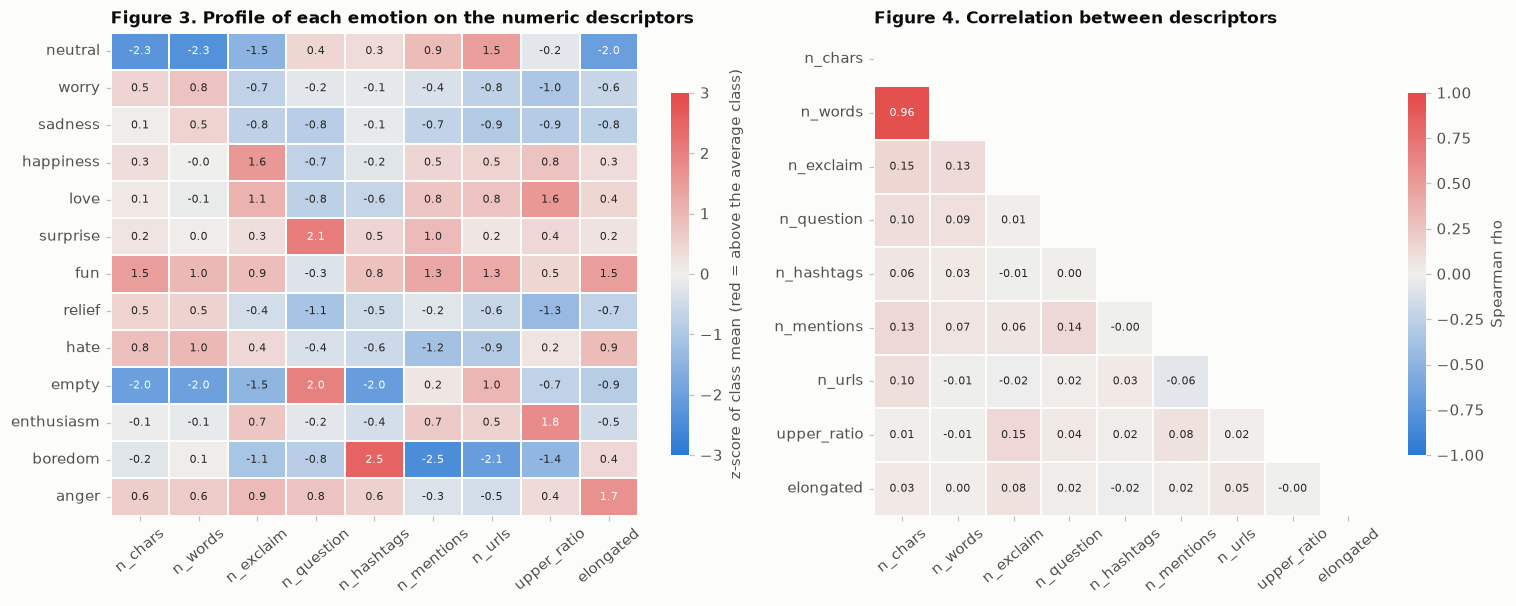

Strongest descriptor correlations: n_words ~ n_chars: +0.96; n_exclaim ~ n_chars: +0.15; upper_ratio ~ n_exclaim: +0.15


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.05, 1]})
prof = meta_c.groupby(df_clean["emotion"].values).mean().loc[cls.index]
z = (prof - prof.mean()) / prof.std(ddof=0)
sns.heatmap(z, cmap=DIV, center=0, vmin=-3, vmax=3, annot=True, fmt=".1f", annot_kws={"size": 7.5}, linewidths=1,
            linecolor=SURFACE, cbar_kws={"shrink": 0.75, "label": "z-score of class mean (red = above the average class)"}, ax=ax1)
ax1.set_title("Figure 3. Profile of each emotion on the numeric descriptors")
ax1.set_ylabel(""); ax1.tick_params(axis="x", rotation=40)

corr = meta_c.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
sns.heatmap(corr, cmap=DIV, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5}, mask=mask,
            linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.75, "label": "Spearman rho"}, ax=ax2)
ax2.set_title("Figure 4. Correlation between descriptors")
ax2.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

hi = corr.where(~mask).stack().sort_values(key=np.abs, ascending=False).head(3)
print("Strongest descriptor correlations:", "; ".join(f"{a} ~ {b}: {v:+.2f}" for (a, b), v in hi.items()))

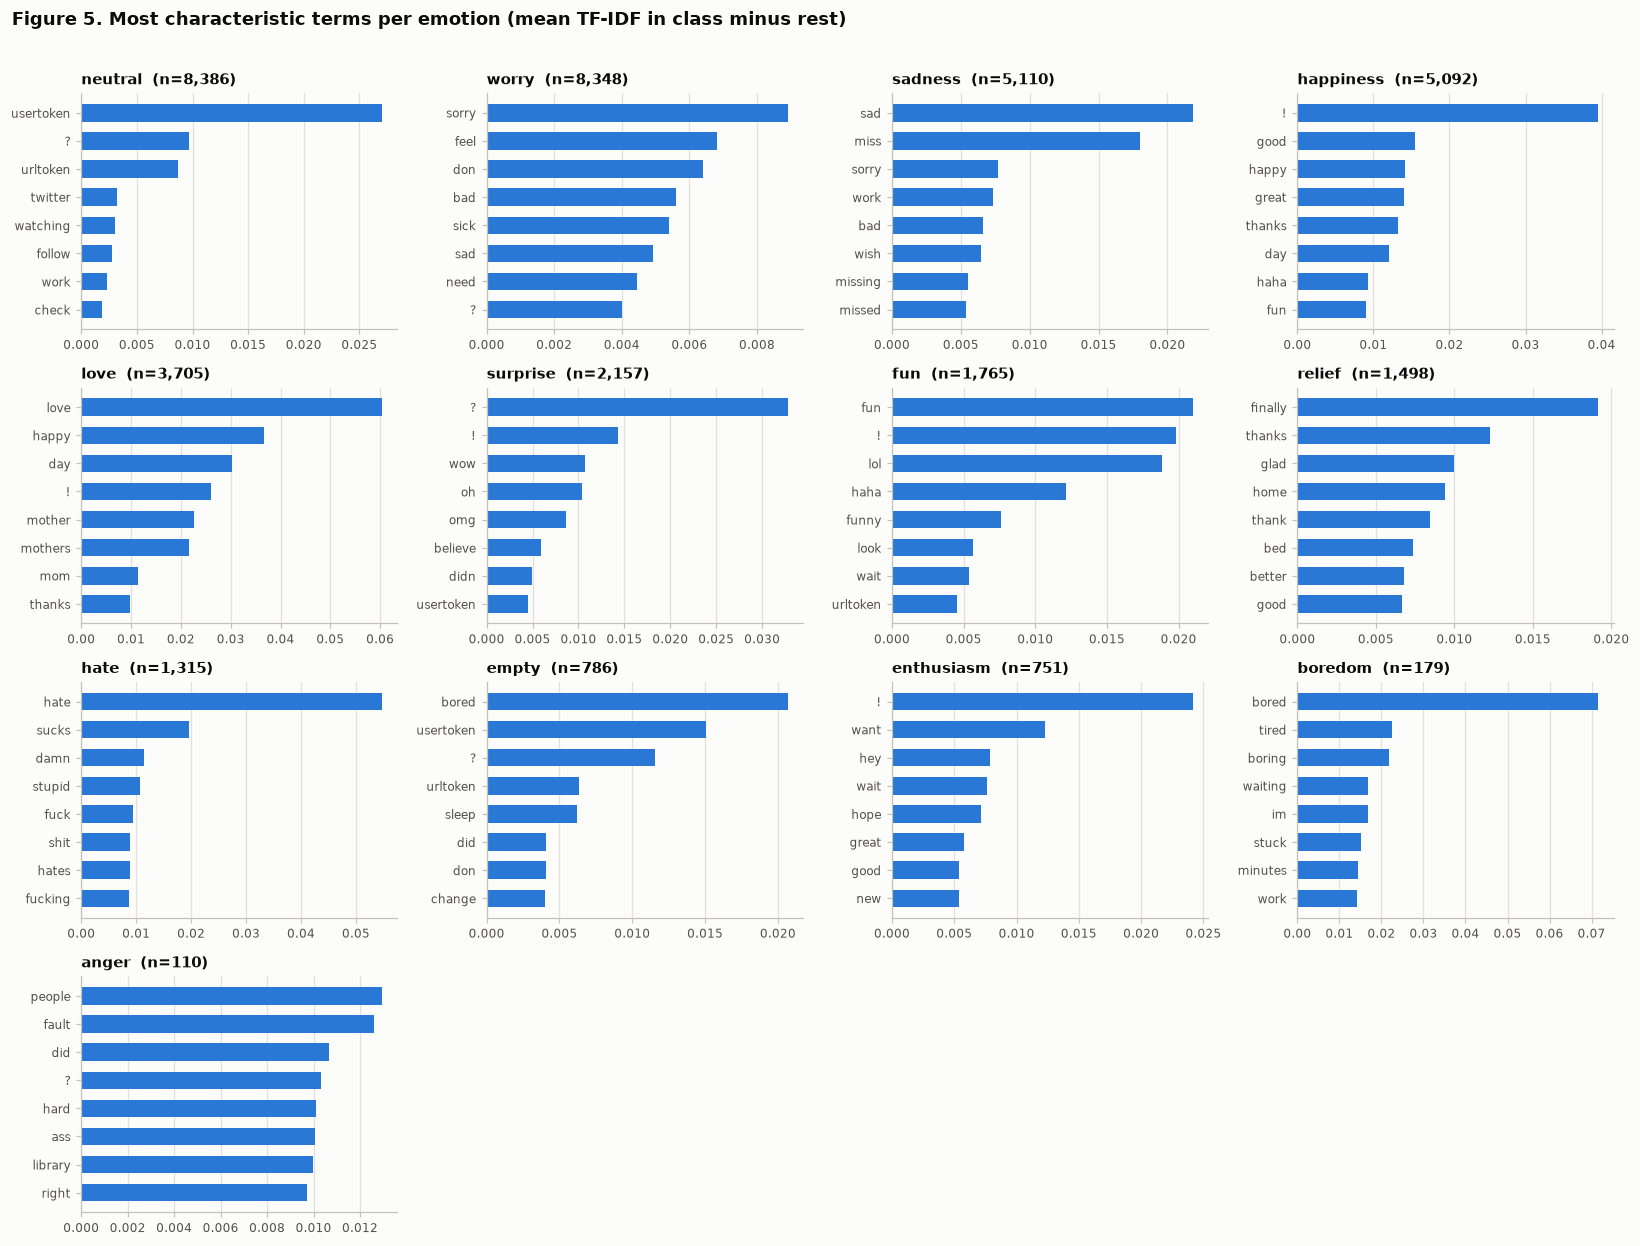

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

tv = TfidfVectorizer(preprocessor=clean_text, token_pattern=TOKEN_PATTERN, min_df=5, max_features=20000,
                     sublinear_tf=True, stop_words="english")   # stop-words removed ONLY for this exploratory view
Xe = tv.fit_transform(df_clean["text"])
terms = np.array(tv.get_feature_names_out())
classes_by_freq = list(cls.index)

fig, axes = plt.subplots(4, 4, figsize=(15, 11.5))
axes = axes.ravel()
for ax, c in zip(axes, classes_by_freq):
    m = (df_clean["emotion"] == c).to_numpy()
    diff = np.asarray(Xe[m].mean(axis=0)).ravel() - np.asarray(Xe[~m].mean(axis=0)).ravel()
    top = np.argsort(diff)[-8:]
    ax.barh(terms[top], diff[top], color=BLUE, height=0.62)
    ax.set_title(f"{c}  (n={m.sum():,})", fontsize=9.5)
    ax.tick_params(labelsize=8)
    grid(ax, "x")
for ax in axes[len(classes_by_freq):]:
    ax.axis("off")
fig.suptitle("Figure 5. Most characteristic terms per emotion (mean TF-IDF in class minus rest)", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

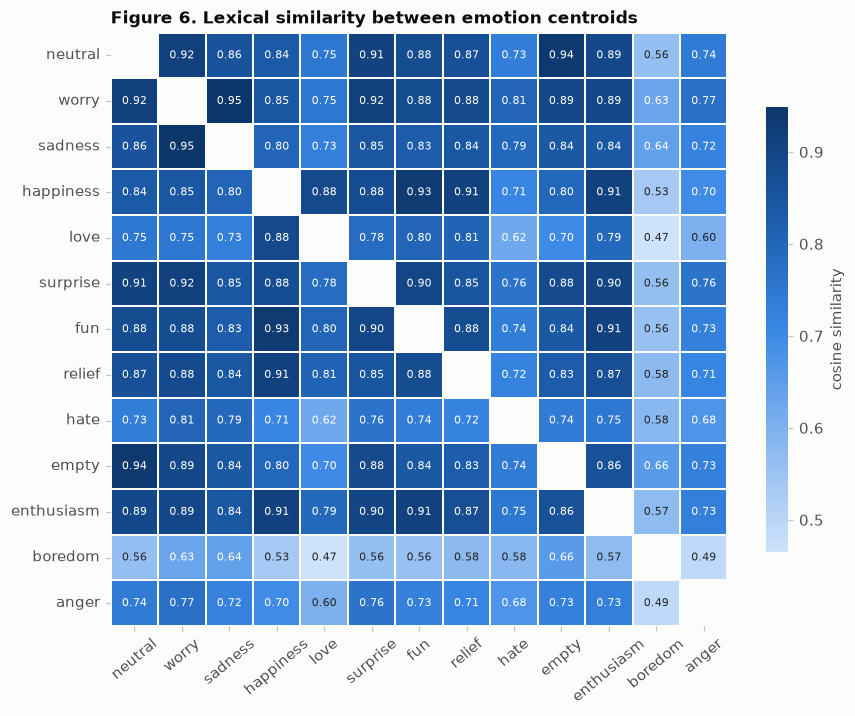

Most similar emotion pairs: worry/sadness (0.95); neutral/empty (0.94); happiness/fun (0.93); worry/surprise (0.92); neutral/worry (0.92)


In [15]:
cent = normalize(np.vstack([np.asarray(Xe[(df_clean["emotion"] == c).to_numpy()].mean(axis=0)).ravel() for c in classes_by_freq]))
sim = cent @ cent.T
off = sim[~np.eye(len(sim), dtype=bool)]
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(sim, mask=np.eye(len(sim), dtype=bool), cmap=SEQ, vmin=off.min(), vmax=off.max(), annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, xticklabels=classes_by_freq, yticklabels=classes_by_freq, linewidths=1, linecolor=SURFACE,
            cbar_kws={"shrink": 0.75, "label": "cosine similarity"}, ax=ax)
ax.set_title("Figure 6. Lexical similarity between emotion centroids")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

iu = np.triu_indices(len(sim), k=1)
pairs = sorted(zip(sim[iu], np.array(classes_by_freq)[iu[0]], np.array(classes_by_freq)[iu[1]]), reverse=True)[:5]
print("Most similar emotion pairs:", "; ".join(f"{a}/{b} ({s:.2f})" for s, a, b in pairs))

50 SVD components keep 17.2% of the TF-IDF variance (first two: 2.2%)


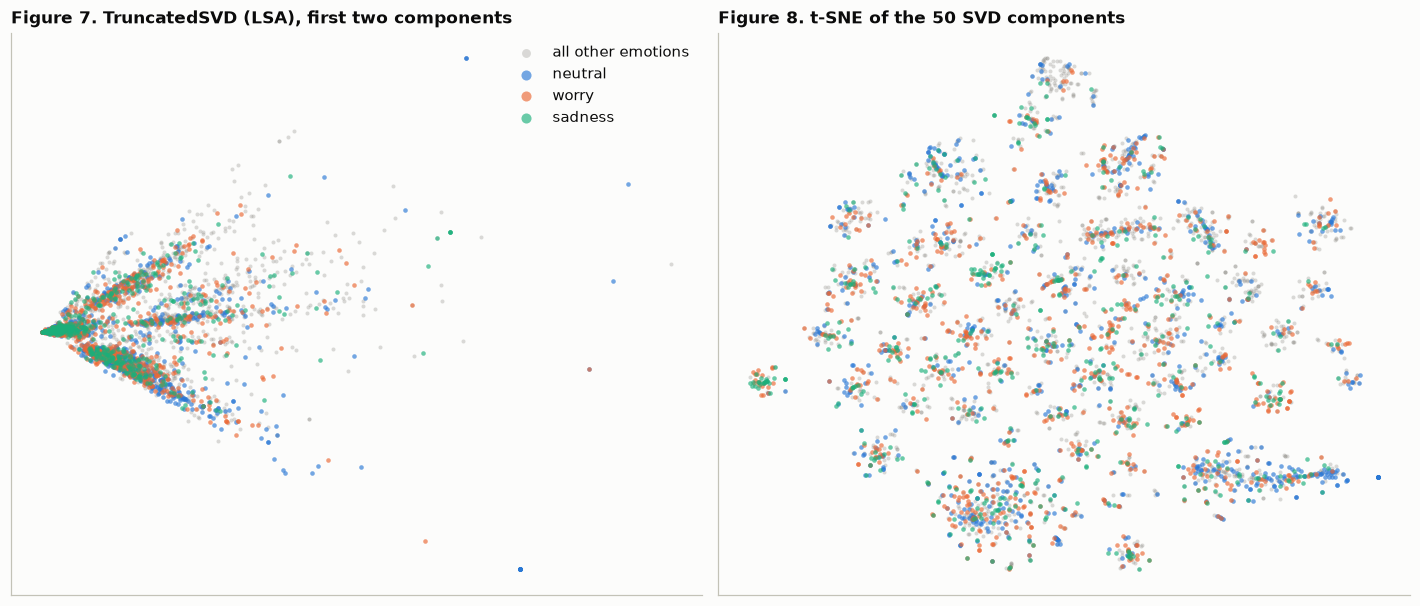

15-NN label purity in SVD space: 18.4%  vs  14.1% expected by chance -> classes are only weakly separated by vocabulary.


In [16]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

svd = TruncatedSVD(n_components=50, random_state=SEED)
Z50 = svd.fit_transform(Xe)
print(f"50 SVD components keep {svd.explained_variance_ratio_.sum():.1%} of the TF-IDF variance "
      f"(first two: {svd.explained_variance_ratio_[:2].sum():.1%})")

idx = rng.choice(len(df_clean), size=min(TSNE_SAMPLE, len(df_clean)), replace=False)
lab = df_clean["emotion"].to_numpy()[idx]
T2 = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z50[idx])

top3 = list(cls.index[:3])
colors = dict(zip(top3, [BLUE, ORANGE, AQUA]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (XY, ttl) in zip(axes, [(Z50[idx, :2], "Figure 7. TruncatedSVD (LSA), first two components"), (T2, "Figure 8. t-SNE of the 50 SVD components")]):
    other = ~np.isin(lab, top3)
    ax.scatter(XY[other, 0], XY[other, 1], s=7, color=GRAY, alpha=0.30, linewidths=0, label="all other emotions")
    for c in top3:
        m = lab == c
        ax.scatter(XY[m, 0], XY[m, 1], s=9, color=colors[c], alpha=0.65, linewidths=0, label=c)
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=2.2, loc="best")
plt.tight_layout(); plt.show()

nb = NearestNeighbors(n_neighbors=16, metric="cosine").fit(Z50[idx]).kneighbors(Z50[idx])[1]
purity = (lab[nb[:, 1:]] == lab[:, None]).mean()
chance = (pd.Series(lab).value_counts(normalize=True) ** 2).sum()
print(f"15-NN label purity in SVD space: {purity:.1%}  vs  {chance:.1%} expected by chance "
      f"-> classes are only weakly separated by vocabulary.")

### 6. Research questions and hypotheses

- **RQ1.** Do tweets of different emotions differ in length? *H0:* the distribution of words per tweet is the same for all 13 emotions; *H1:* at least one emotion differs. Kruskal–Wallis test (non-parametric: lengths are discrete and right-skewed), effect size ε².
- **RQ2.** Do tweets with positive emotions (*happiness, enthusiasm, fun, love, relief*) use exclamation marks more than tweets with negative emotions (*sadness, worry, hate, anger, boredom, empty*)? *H0:* no difference; *H1:* positive > negative. One-sided Mann–Whitney U test (+ χ² test on the share of tweets containing at least one `!`). Neutral and surprise are left out because their valence is ambiguous.
- **H3 (modelling hypothesis, evaluated in the ML part).** Because the classes overlap lexically (Figures 6-8) and are heavily imbalanced, the best achievable **macro-F1 will be far below accuracy**, and no model will exceed a modest accuracy; accuracy alone would therefore be a misleading yardstick.

RQ1  Kruskal-Wallis: H = 955.0, p = 8.99e-197, epsilon^2 = 0.0244 (small effect)
     -> reject H0 (lengths differ across emotions)

RQ2  share of tweets with '!': positive 40.8% vs negative 25.0%
     Mann-Whitney U (one-sided, positive > negative): p = 1.8e-181; P(positive has more '!' than negative) = 0.581 (0.5 = no effect)
     chi-square on the share with '!': chi2 = 814.7, p = 3.38e-179
     -> reject H0 (positive emotions use more '!')


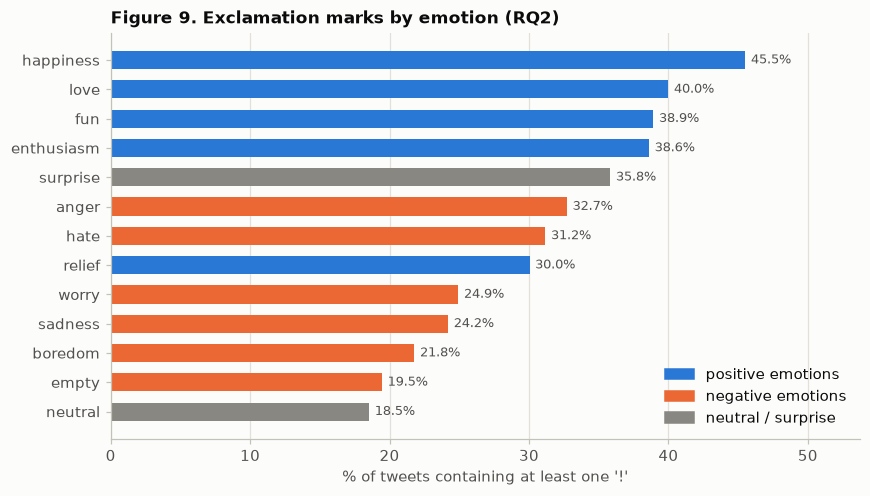

In [17]:
FINDINGS = {}
alpha = 0.05
emo = df_clean["emotion"].to_numpy()

groups = [meta_c.loc[emo == c, "n_words"].to_numpy() for c in cls.index]
H, p1 = stats.kruskal(*groups)
eps2 = H / (len(df_clean) - 1)
size1 = "negligible" if eps2 < 0.01 else "small" if eps2 < 0.06 else "medium" if eps2 < 0.14 else "large"
FINDINGS["RQ1"] = dict(H=H, p=p1, eps2=eps2)
print(f"RQ1  Kruskal-Wallis: H = {H:.1f}, {p_str(p1)}, epsilon^2 = {eps2:.4f} ({size1} effect)")
print("     ->", "reject H0 (lengths differ across emotions)" if p1 < alpha else "fail to reject H0")

POS = [c for c in ["happiness", "enthusiasm", "fun", "love", "relief"] if c in set(cls.index)]
NEG = [c for c in ["sadness", "worry", "hate", "anger", "boredom", "empty"] if c in set(cls.index)]
a = meta_c.loc[np.isin(emo, POS), "n_exclaim"].to_numpy()
b = meta_c.loc[np.isin(emo, NEG), "n_exclaim"].to_numpy()
U, p2 = stats.mannwhitneyu(a, b, alternative="greater")
cles = U / (len(a) * len(b))
tab = np.array([[(a > 0).sum(), (a == 0).sum()], [(b > 0).sum(), (b == 0).sum()]])
chi2, p2b, _, _ = stats.chi2_contingency(tab)
FINDINGS["RQ2"] = dict(U=U, p=p2, cles=cles, share_pos=(a > 0).mean(), share_neg=(b > 0).mean())
print(f"\nRQ2  share of tweets with '!': positive {np.mean(a > 0):.1%} vs negative {np.mean(b > 0):.1%}")
print(f"     Mann-Whitney U (one-sided, positive > negative): {p_str(p2)}; P(positive has more '!' than negative) = {cles:.3f} (0.5 = no effect)")
print(f"     chi-square on the share with '!': chi2 = {chi2:.1f}, {p_str(p2b)}")
print("     ->", "reject H0 (positive emotions use more '!')" if p2 < alpha else "fail to reject H0")

share = pd.Series({c: (meta_c.loc[emo == c, "n_exclaim"] > 0).mean() for c in cls.index}).sort_values()
grp_color = {c: (BLUE if c in POS else ORANGE if c in NEG else GRAY) for c in share.index}
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(share.index, share.values * 100, color=[grp_color[c] for c in share.index], height=0.62)
for i, (c, v) in enumerate(share.items()):
    ax.text(v * 100 + 0.4, i, f"{v:.1%}", va="center", fontsize=8.5, color=INK2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="positive emotions"), Patch(color=ORANGE, label="negative emotions"), Patch(color=GRAY, label="neutral / surprise")],
          loc="lower right")
ax.set_xlim(0, share.max() * 100 * 1.18)
ax.set_xlabel("% of tweets containing at least one '!'")
ax.set_title("Figure 9. Exclamation marks by emotion (RQ2)")
grid(ax, "x")
plt.tight_layout(); plt.show()

### 7. Preprocessing decisions (summary)

| Decision | Choice | Reason |
|---|---|---|
| Missing values | none present; rows with missing text/label would be dropped | nothing to impute for free text |
| Duplicates | near-duplicate tweets (same normalised text) reduced to one copy | prevents train/test leakage and double counting retweets |
| Label conflicts | all copies of a text with ≠ 1 distinct label dropped | the target is undefined for them; keeping one arbitrarily would add label noise to the test set |
| Outliers | kept | genuine text, not errors; TF-IDF rows are L2-normalised |
| Text normalisation | see table in section 2 | keeps emotion-bearing tokens (negations, `!`, `?`, emoticons) |
| Class imbalance | handled with class weights (not resampling) and judged with macro-F1 | resampling text creates duplicates/leakage risk; weights keep the real distribution intact |
| Scaling / vectorisation | TF-IDF is **fitted on training data only**, inside scikit-learn pipelines | no information from validation/test enters the vocabulary or IDF weights |
| Splits | stratified 64 % train / 16 % validation / 20 % test, fixed seed | the test set is touched once for the final report |

## Machine Learning (and/or other algorithm aplication)

Define the ML problem formally. Prepare the dataset for model training. Perform feature engineering where appropriate. Select at least 3 different ML algorithms. Train and validate the models. Perform hyperparameter optimization for at least one model. Explain the model selection process.

For certain tasks (recommendation systems, TF-IDF nlp) use different, non-ML algorithms (at least 2 different). 

Compare algorithms using appropriate metrics: accuracy, F1 (classification tasks), MSE (regression/ ts prediction), etc. Visualize models performance. Identify strengths and weaknesses of each algorithm.

### 1. Formal problem definition

Let $\mathcal{X}$ be the set of tweets (finite strings) and $\mathcal{Y}=\{1,\dots,K\}$, $K=13$, the set of emotions. Given a labelled sample $\{(x_i,y_i)\}_{i=1}^{n}$ drawn i.i.d. from an unknown distribution $P$ on $\mathcal{X}\times\mathcal{Y}$, we want a classifier $f:\mathcal{X}\to\mathcal{Y}$ that minimises the expected 0-1 loss $\mathbb{E}_{(x,y)\sim P}\,\mathbf{1}[f(x)\neq y]$. The class distribution is strongly imbalanced, so the **primary metric is macro-F1**,

$$\mathrm{F1}_{\text{macro}}=\frac1K\sum_{k=1}^{K}\frac{2\,\mathrm{TP}_k}{2\,\mathrm{TP}_k+\mathrm{FP}_k+\mathrm{FN}_k},$$

which weights every emotion equally; accuracy, weighted-F1 and balanced accuracy are reported as well.

**Protocol.** (i) hyper-parameters are tuned by 3-fold stratified cross-validation *inside the training split*; (ii) all models are compared on the validation split, and the best one is selected there; (iii) the test split is used only for the final numbers. Models are trained on the training split only (no re-fit on train+validation), which keeps the three splits strictly separate.

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, MaxAbsScaler, FunctionTransformer
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline, FeatureUnion

le = LabelEncoder().fit(df_clean["emotion"])
CLASSES = le.classes_
K = len(CLASSES)
X_all = df_clean["text"].to_numpy()
y_all = le.transform(df_clean["emotion"])
norm_all = df_clean["text_norm"].to_numpy()

idx_all = np.arange(len(df_clean))
idx_trval, idx_test = train_test_split(idx_all, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.20, stratify=y_all[idx_trval], random_state=SEED)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
X_trval, y_trval = X_all[idx_trval], y_all[idx_trval]

def share(y):
    return pd.Series(np.bincount(y, minlength=K) / len(y), index=CLASSES)

split_tbl = pd.DataFrame({"train": share(y_train), "val": share(y_val), "test": share(y_test), "all": share(y_all)})
print(f"train {len(y_train):,} | validation {len(y_val):,} | test {len(y_test):,}")
display((split_tbl * 100).round(2).T)
print("max |split share - overall share| = %.2f percentage points" % (split_tbl.sub(split_tbl["all"], axis=0).abs().max().max() * 100))

train 25,088 | validation 6,273 | test 7,841


,anger,boredom,empty,enthusiasm,fun,happiness,hate,love,neutral,relief,sadness,surprise,worry
train,0.28,0.45,2.00,1.92,4.5,12.99,3.36,9.45,21.39,3.82,13.03,5.5,21.29
val,0.27,0.46,2.01,1.91,4.5,12.99,3.35,9.45,21.39,3.83,13.04,5.5,21.30
test,0.28,0.46,2.00,1.91,4.5,13.00,3.35,9.45,21.39,3.83,13.03,5.5,21.30
all,0.28,0.46,2.00,1.92,4.5,12.99,3.35,9.45,21.39,3.82,13.04,5.5,21.29


max |split share - overall share| = 0.01 percentage points


In [19]:
def score_row(y, p):
    lab = np.arange(K)
    return dict(acc=accuracy_score(y, p),
                macro_f1=f1_score(y, p, average="macro", labels=lab, zero_division=0),
                weighted_f1=f1_score(y, p, average="weighted", labels=lab, zero_division=0),
                bal_acc=balanced_accuracy_score(y, p))

RESULTS = {}
def register(name, family, val_pred, test_pred, fit_s, model=None):
    RESULTS[name] = dict(family=family, val_pred=np.asarray(val_pred), test_pred=np.asarray(test_pred),
                         fit_s=float(fit_s), model=model)

# ---- baselines: any real model must beat these -------------------------------------------------
from sklearn.dummy import DummyClassifier
for name, strat in [("Baseline: majority class", "most_frequent"), ("Baseline: stratified random", "stratified")]:
    d = DummyClassifier(strategy=strat, random_state=SEED)
    t0 = time.time(); d.fit(np.zeros((len(y_train), 1)), y_train); fit_s = time.time() - t0
    register(name, "Baseline", d.predict(np.zeros((len(y_val), 1))), d.predict(np.zeros((len(y_test), 1))), fit_s)
    s = score_row(y_val, RESULTS[name]["val_pred"])
    print(f"{name:30s} val accuracy {s['acc']:.3f} | val macro-F1 {s['macro_f1']:.3f}")

Baseline: majority class       val accuracy 0.214 | val macro-F1 0.027
Baseline: stratified random    val accuracy 0.136 | val macro-F1 0.074


### 2. Feature engineering

Features come from three sources, all computed inside pipelines so that the vocabulary and IDF weights only ever see training text:

1. **word TF-IDF** (uni- and bi-grams, sub-linear term frequency, `min_df=2`), with emoticons, `!` and `?` kept as tokens;
2. **character TF-IDF** (`char_wb` 2-5-grams): robust to misspellings, slang and elongation (*luv*, *soooo*);
3. **numeric descriptors** (length, punctuation, capital-letter share, ...), log-transformed and scaled.

An ablation on the validation split (same linear SVM each time) shows which of these pay off. It also tests the earlier claim that stop-words should be kept.

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

def tfidf_word(ngram=(1, 2), min_df=2, max_features=None, stop_words=None):
    return TfidfVectorizer(preprocessor=clean_text, token_pattern=TOKEN_PATTERN, ngram_range=ngram, min_df=min_df,
                           max_features=max_features, sublinear_tf=True, stop_words=stop_words)

def tfidf_char(ngram=(2, 5), min_df=3, max_features=150_000):
    return TfidfVectorizer(preprocessor=clean_text, analyzer="char_wb", ngram_range=ngram, min_df=min_df,
                           max_features=max_features, sublinear_tf=True)

def meta_matrix(texts):
    s = pd.Series(np.asarray(texts, dtype=object))
    return np.log1p(meta_features(s).to_numpy(dtype=float))

def _meta_names_out(transformer, input_features):
    return np.array(META_COLS, dtype=object)

def meta_block(scale=True):
    ft = FunctionTransformer(meta_matrix, validate=False, feature_names_out=_meta_names_out)
    return Pipeline([("m", ft), ("s", MaxAbsScaler())]) if scale else ft

variants = {
    "A  word 1-grams":                    lambda: tfidf_word(ngram=(1, 1)),
    "B  word 1-2-grams":                  lambda: tfidf_word(),
    "B' word 1-2-grams, stop-words out":  lambda: tfidf_word(stop_words="english"),
    "C  word 1-2 + char 2-5":             lambda: FeatureUnion([("word", tfidf_word()), ("char", tfidf_char())]),
    "D  C + numeric descriptors":         lambda: FeatureUnion([("word", tfidf_word()), ("char", tfidf_char()), ("meta", meta_block())]),
}
rows = []
for name, make in variants.items():
    pipe = Pipeline([("f", make()), ("clf", LinearSVC(C=0.3, class_weight="balanced", random_state=SEED))])
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    s = score_row(y_val, pipe.predict(X_val))
    rows.append(dict(features=name, n_features=pipe.named_steps["f"].transform(X_val[:5]).shape[1], val_acc=s["acc"],
                     val_macro_f1=s["macro_f1"], fit_s=fit_s))
abl = pd.DataFrame(rows).set_index("features")
display(abl.round(4))

USE_META = bool(abl.loc["D  C + numeric descriptors", "val_macro_f1"] > abl.loc["C  word 1-2 + char 2-5", "val_macro_f1"])
stop_effect = abl.loc["B' word 1-2-grams, stop-words out", "val_macro_f1"] - abl.loc["B  word 1-2-grams", "val_macro_f1"]
print(f"\nDecision: numeric descriptors {'ARE' if USE_META else 'are NOT'} added to the linear feature set (by validation macro-F1).")
print(f"Removing stop-words changes validation macro-F1 by {stop_effect:+.4f} -> "
      f"{'stop-words are kept (removal does not help)' if stop_effect <= 0 else 'removal helps slightly, but we keep them for negation handling'}.")

def make_linear_features():
    parts = [("word", tfidf_word()), ("char", tfidf_char())]
    if USE_META:
        parts.append(("meta", meta_block()))
    return FeatureUnion(parts)

,n_features,val_acc,val_macro_f1,fit_s
features,,,,
A word 1-grams,9462,0.2527,0.1834,1.7210
B word 1-2-grams,37975,0.2721,0.1857,1.9567
"B' word 1-2-grams, stop-words out",22100,0.2508,0.1776,2.5878
C word 1-2 + char 2-5,91725,0.2946,0.1988,21.0146
D C + numeric descriptors,91734,0.2965,0.1995,22.3212



Decision: numeric descriptors ARE added to the linear feature set (by validation macro-F1).
Removing stop-words changes validation macro-F1 by -0.0081 -> stop-words are kept (removal does not help).


### 3. Algorithms

| Family | Algorithm | Features | Imbalance handling | Tuning |
|---|---|---|---|---|
| ML (linear) | **Linear SVM** | word + char TF-IDF | `class_weight` (tuned: none / balanced) | grid search on C × class_weight |
| ML (linear) | **Logistic Regression** (multinomial) | word + char TF-IDF | balanced weights | grid search on C |
| ML (probabilistic) | **Complement Naive Bayes** | word + char TF-IDF | built in (complement statistics) | grid search on alpha |
| ML (ensemble) | **Random Forest** | 5 000 word TF-IDF + descriptors | `balanced_subsample` | fixed, standard settings |
| ML (ensemble) | **XGBoost** | 5 000 word TF-IDF + descriptors | balanced sample weights | early stopping on a held-out part of train |
| Non-ML | **Lexicon rules** | hand-written emotion lexicon | none (no training at all) | none |
| Non-ML / IR | **TF-IDF cosine centroid** (Rocchio) | word + char TF-IDF | none | none |
| Non-ML / IR | **TF-IDF cosine k-NN** retrieval (k = 25) | word + char TF-IDF | none | none |

The assignment asks for at least three ML algorithms and, for TF-IDF text tasks, at least two non-ML algorithms; this table has five and three. Tree ensembles get a smaller vocabulary (5 000 terms) because they cannot exploit hundreds of thousands of sparse columns efficiently.

#### 3.1 Linear models and Naive Bayes with hyper-parameter optimisation

A cross-validated grid search optimises **macro-F1** with 3-fold stratified CV *inside the training split*. For every fold the TF-IDF vocabulary and IDF weights are fitted on that fold's training part only and then applied to its held-out part, so no information leaks from the held-out fold. The feature matrices are built once per fold and reused for every hyper-parameter candidate (this is what makes the search affordable). The best candidate is then re-fitted on the whole training split inside a complete pipeline.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from joblib import Parallel, delayed

skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
t0 = time.time()
fold_data = []не 
for tr_i, va_i in skf3.split(X_train, y_train):
    f = make_linear_features().fit(X_train[tr_i])
    fold_data.append((f.transform(X_train[tr_i]), y_train[tr_i], f.transform(X_train[va_i]), y_train[va_i]))
print(f"cross-validation feature matrices built in {time.time() - t0:.0f}s")

def cv_candidate(clf, params, folds, n_classes):
    scores = []
    for Xa, ya, Xb, yb in folds:
        m = clone(clf).set_params(**params).fit(Xa, ya)
        scores.append(f1_score(yb, m.predict(Xb), average="macro", labels=np.arange(n_classes), zero_division=0))
    return scores

SPACES = {
    "Linear SVM (tuned)":          (LinearSVC(random_state=SEED), {"C": [0.05, 0.1, 0.3, 1.0], "class_weight": [None, "balanced"]}),
    "Logistic Regression (tuned)": (LogisticRegression(max_iter=300, class_weight="balanced", random_state=SEED), {"C": [3, 10, 30]}),
    "Complement NB (tuned)":       (ComplementNB(), {"alpha": [0.03, 0.1, 0.3, 1.0]}),
}
TUNING = {}
tuning_rows = []
for name, (clf, space) in SPACES.items():
    t0 = time.time()
    cands = list(ParameterGrid(space))
    all_scores = Parallel(n_jobs=N_JOBS)(delayed(cv_candidate)(clf, c, fold_data, K) for c in cands)
    table = pd.DataFrame([dict(**c, mean_cv=np.mean(sc), std_cv=np.std(sc)) for c, sc in zip(cands, all_scores)])
    best_params = cands[int(table["mean_cv"].idxmax())]
    search_s = time.time() - t0
    pipe = Pipeline([("f", make_linear_features()), ("clf", clone(clf).set_params(**best_params))])
    t0 = time.time(); pipe.fit(X_train, y_train); refit_s = time.time() - t0
    register(name, "ML", pipe.predict(X_val), pipe.predict(X_test), refit_s, model=pipe)
    TUNING[name] = table
    tuning_rows.append(dict(model=name, best_params=str(best_params), cv_macro_f1=table["mean_cv"].max(), search_seconds=search_s))
display(pd.DataFrame(tuning_rows).set_index("model").round(4))

cross-validation feature matrices built in 44s


,best_params,cv_macro_f1,search_seconds
model,,,
Linear SVM (tuned),"{'C': 0.05, 'class_weight': 'balanced'}",0.2095,48.1200
Logistic Regression (tuned),{'C': 3},0.2063,271.8892
Complement NB (tuned),{'alpha': 0.3},0.1808,4.5548


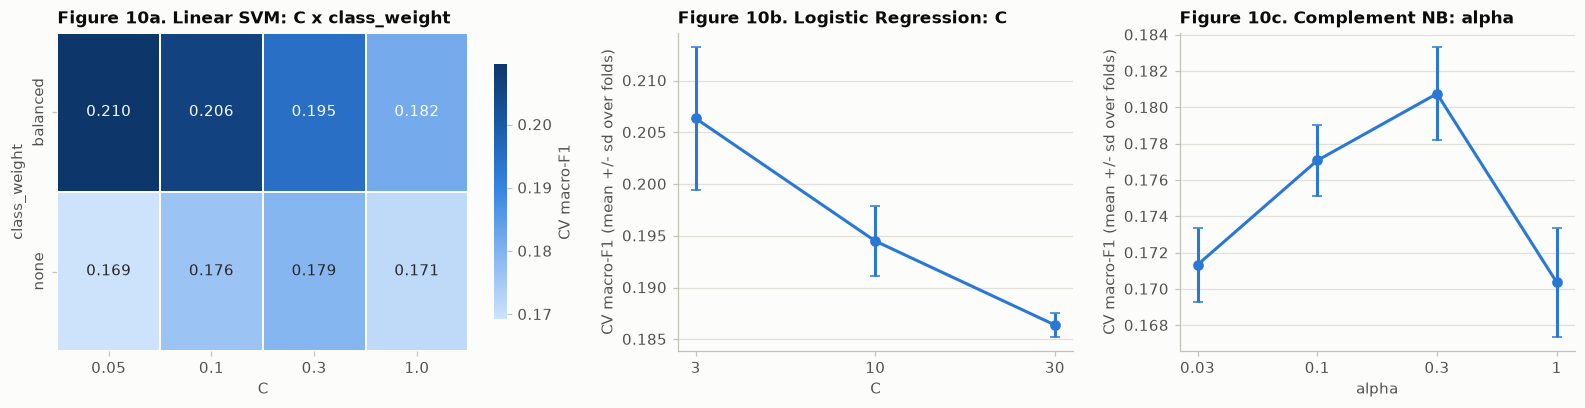

In [22]:
svm_cv = TUNING["Linear SVM (tuned)"].copy()
svm_cv["class_weight"] = svm_cv["class_weight"].fillna("none").astype(str)   # None would be dropped by pivot_table
piv = svm_cv.pivot_table(index="class_weight", columns="C", values="mean_cv")
lr_cv, nb_cv = TUNING["Logistic Regression (tuned)"], TUNING["Complement NB (tuned)"]

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
sns.heatmap(piv, cmap=SEQ, annot=True, fmt=".3f", linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.8, "label": "CV macro-F1"}, ax=axes[0])
axes[0].set_title("Figure 10a. Linear SVM: C x class_weight"); axes[0].set_xlabel("C"); axes[0].set_ylabel("class_weight")
for ax, d, col, ttl in [(axes[1], lr_cv, "C", "Figure 10b. Logistic Regression: C"),
                        (axes[2], nb_cv, "alpha", "Figure 10c. Complement NB: alpha")]:
    ax.errorbar(range(len(d)), d["mean_cv"], yerr=d["std_cv"], color=BLUE, marker="o", markersize=6, linewidth=2, capsize=3)
    ax.set_xticks(range(len(d))); ax.set_xticklabels([f"{v:g}" for v in d[col]])
    ax.set_xlabel(col); ax.set_ylabel("CV macro-F1 (mean +/- sd over folds)")
    ax.set_title(ttl); grid(ax, "y")
plt.tight_layout(); plt.show()

#### 3.2 Random Forest and XGBoost

Both use the same compact feature set (5 000 word 1-2-gram TF-IDF terms + the nine numeric descriptors). XGBoost is trained with early stopping on 10 % of the training split (not on the validation split, so validation scores stay honest).

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb

def make_tree_features(max_features=5000):
    return FeatureUnion([("word", tfidf_word(ngram=(1, 2), min_df=3, max_features=max_features)),
                         ("meta", meta_block(scale=False))])

tree_feats = make_tree_features().fit(X_train)
Xtr_t, Xva_t, Xte_t = (tree_feats.transform(X) for X in (X_train, X_val, X_test))
tree_names = np.array([n.replace("word__", "").replace("meta__", "#") for n in tree_feats.get_feature_names_out()])
print("tree feature matrix:", Xtr_t.shape)

rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", class_weight="balanced_subsample",
                            n_jobs=N_JOBS, random_state=SEED)
t0 = time.time(); rf.fit(Xtr_t, y_train); rf_s = time.time() - t0
register("Random Forest", "ML", rf.predict(Xva_t), rf.predict(Xte_t), rf_s, model=rf)

XGB_PARAMS = dict(n_estimators=600, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                  tree_method="hist", objective="multi:softprob", eval_metric="mlogloss",
                  early_stopping_rounds=30, n_jobs=N_JOBS, random_state=SEED)
fit_i, es_i = train_test_split(np.arange(len(y_train)), test_size=0.10, stratify=y_train, random_state=SEED)
w_train = compute_sample_weight("balanced", y_train)
xgb_clf = xgb.XGBClassifier(**XGB_PARAMS)
t0 = time.time()
xgb_clf.fit(Xtr_t[fit_i], y_train[fit_i], sample_weight=w_train[fit_i],
            eval_set=[(Xtr_t[es_i], y_train[es_i])], verbose=False)
xgb_s = time.time() - t0
register("XGBoost", "ML", xgb_clf.predict(Xva_t), xgb_clf.predict(Xte_t), xgb_s, model=xgb_clf)
print(f"Random Forest fitted in {rf_s:.0f}s | XGBoost fitted in {xgb_s:.0f}s, best iteration = {xgb_clf.best_iteration}")

tree feature matrix: (25088, 5009)
Random Forest fitted in 26s | XGBoost fitted in 297s, best iteration = 595


#### 3.3 Non-ML / information-retrieval algorithms

1. **Lexicon rules** use no training data at all: a small hand-written emotion lexicon (written before looking at any results), negation handling (a match directly after *not / no / never / don* is ignored), a bonus for repeated `!` and a default of *neutral* when nothing matches.
2. **TF-IDF cosine centroid (Rocchio)** represents every emotion by the mean of its normalised TF-IDF vectors and assigns a tweet to the most cosine-similar centroid.
3. **TF-IDF cosine k-NN retrieval** finds the 25 most similar training tweets and lets them vote, weighted by similarity.

In [24]:
LEXICON = {
    "anger":      "angry mad furious pissed rage annoyed annoying irritated outraged livid fuming",
    "hate":       "hate hated hates hating despise disgusting sucks worst stupid awful horrible terrible ugh",
    "boredom":    "bored boring boredom dull yawn tedious",
    "sadness":    "sad cry crying cried depressed lonely miss missing heartbroken tears unhappy sadly sorry grief :(",
    "worry":      "worried worry worrying anxious nervous scared afraid fear stress stressed sick ill hurt pain exam hoping hope",
    "love":       "love loved loves loving luv xoxo babe honey sweetheart adore adorable <3",
    "happiness":  "happy glad great good awesome yay smile smiling nice wonderful blessed lovely beautiful :) ;)",
    "fun":        "fun funny party lol lmao haha hahaha hilarious game playing dance concert",
    "enthusiasm": "excited excitement exciting amazing woohoo woo pumped thrilled",
    "relief":     "relief relieved finally phew thankful grateful safe",
    "surprise":   "wow omg surprise surprised shocked unexpected whoa unbelievable really",
    "empty":      "empty nothing numb blank whatever meh",
}
WORD2CLASS = {}
for c, ws in LEXICON.items():
    for w in ws.split():
        assert w not in WORD2CLASS, f"lexicon word {w!r} listed twice"
        WORD2CLASS[w] = c
TOK = re.compile(TOKEN_PATTERN)
NEGATORS = {"not", "no", "never", "don", "dont", "isn", "cant", "didn", "wasn", "won", "couldn"}
cls2id = {c: i for i, c in enumerate(CLASSES)}
DEFAULT_CLASS = "neutral" if "neutral" in cls2id else CLASSES[0]

def lexicon_predict_one(text):
    toks = TOK.findall(clean_text(text))
    scores = {}
    for i, t in enumerate(toks):
        c = WORD2CLASS.get(t)
        if c is not None and not (i > 0 and toks[i - 1] in NEGATORS):
            scores[c] = scores.get(c, 0) + 1
    if toks.count("!") >= 2:
        scores["enthusiasm"] = scores.get("enthusiasm", 0) + 0.5
    if not scores:
        return cls2id[DEFAULT_CLASS]
    best = max(sorted(scores), key=scores.get)
    return cls2id.get(best, cls2id[DEFAULT_CLASS])

lex_pred = lambda X: np.array([lexicon_predict_one(t) for t in X])
t0 = time.time(); lv, lt = lex_pred(X_val), lex_pred(X_test); lex_s = time.time() - t0
register("Lexicon rules (no training)", "Non-ML", lv, lt, 0.0)
print(f"lexicon coverage: {np.mean([any(t in WORD2CLASS for t in TOK.findall(clean_text(x))) for x in X_val]):.1%} of validation tweets contain at least one lexicon word")

from sklearn.neighbors import KNeighborsClassifier
lin_feats = make_linear_features().fit(X_train)
Xtr_l, Xva_l, Xte_l = (lin_feats.transform(X) for X in (X_train, X_val, X_test))

t0 = time.time()
centroids = normalize(np.vstack([np.asarray(normalize(Xtr_l[y_train == k]).mean(axis=0)).ravel() for k in range(K)]))
cent_s = time.time() - t0
cent_pred = lambda X: np.asarray(normalize(X) @ centroids.T).argmax(axis=1)
register("TF-IDF cosine centroid", "Non-ML", cent_pred(Xva_l), cent_pred(Xte_l), cent_s)

knn = KNeighborsClassifier(n_neighbors=25, metric="cosine", weights="distance", algorithm="brute", n_jobs=N_JOBS)
t0 = time.time(); knn.fit(Xtr_l, y_train); knn_s = time.time() - t0
register("TF-IDF cosine kNN (k=25)", "Non-ML", knn.predict(Xva_l), knn.predict(Xte_l), knn_s)
print("done: lexicon, centroid and kNN registered")

lexicon coverage: 44.0% of validation tweets contain at least one lexicon word
done: lexicon, centroid and kNN registered


### 4. Comparison of all algorithms

Models are ranked by **validation macro-F1** (that is the selection criterion); test-set numbers are shown next to them for the final report.

In [25]:
rows = []
for name, r in RESULTS.items():
    v, t = score_row(y_val, r["val_pred"]), score_row(y_test, r["test_pred"])
    rows.append(dict(model=name, family=r["family"], val_acc=v["acc"], val_macro_f1=v["macro_f1"],
                     test_acc=t["acc"], test_macro_f1=t["macro_f1"], test_weighted_f1=t["weighted_f1"],
                     test_bal_acc=t["bal_acc"], fit_seconds=r["fit_s"]))
res = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(res.round(4))

contenders = res[res.family != "Baseline"]
BEST = contenders.iloc[0]["model"]
print(f"\nSelected model (highest validation macro-F1 among non-baselines): {BEST}")

,model,family,val_acc,val_macro_f1,test_acc,test_macro_f1,test_weighted_f1,test_bal_acc,fit_seconds
0,Linear SVM (tuned),ML,0.3038,0.2095,0.3076,0.2156,0.3206,0.2386,17.5661
1,Logistic Regression (tuned),ML,0.3102,0.2053,0.3178,0.2158,0.3212,0.2216,80.5537
2,XGBoost,ML,0.2863,0.1818,0.2996,0.2032,0.3040,0.2085,297.2163
3,Complement NB (tuned),ML,0.3247,0.1806,0.3257,0.1798,0.3059,0.1833,6.9504
4,TF-IDF cosine centroid,Non-ML,0.2455,0.1652,0.2451,0.1644,0.2423,0.1921,0.1757
5,Lexicon rules (no training),Non-ML,0.2745,0.1580,0.2736,0.1712,0.2356,0.1942,0.0000
6,Random Forest,ML,0.3201,0.1521,0.3332,0.1576,0.2905,0.1626,26.0043
7,TF-IDF cosine kNN (k=25),Non-ML,0.2922,0.1325,0.2986,0.1330,0.2618,0.1412,0.0699
8,Baseline: stratified random,Baseline,0.1355,0.0744,0.1400,0.0736,0.1404,0.0736,0.0007
9,Baseline: majority class,Baseline,0.2139,0.0271,0.2139,0.0271,0.0754,0.0769,0.0014



Selected model (highest validation macro-F1 among non-baselines): Linear SVM (tuned)


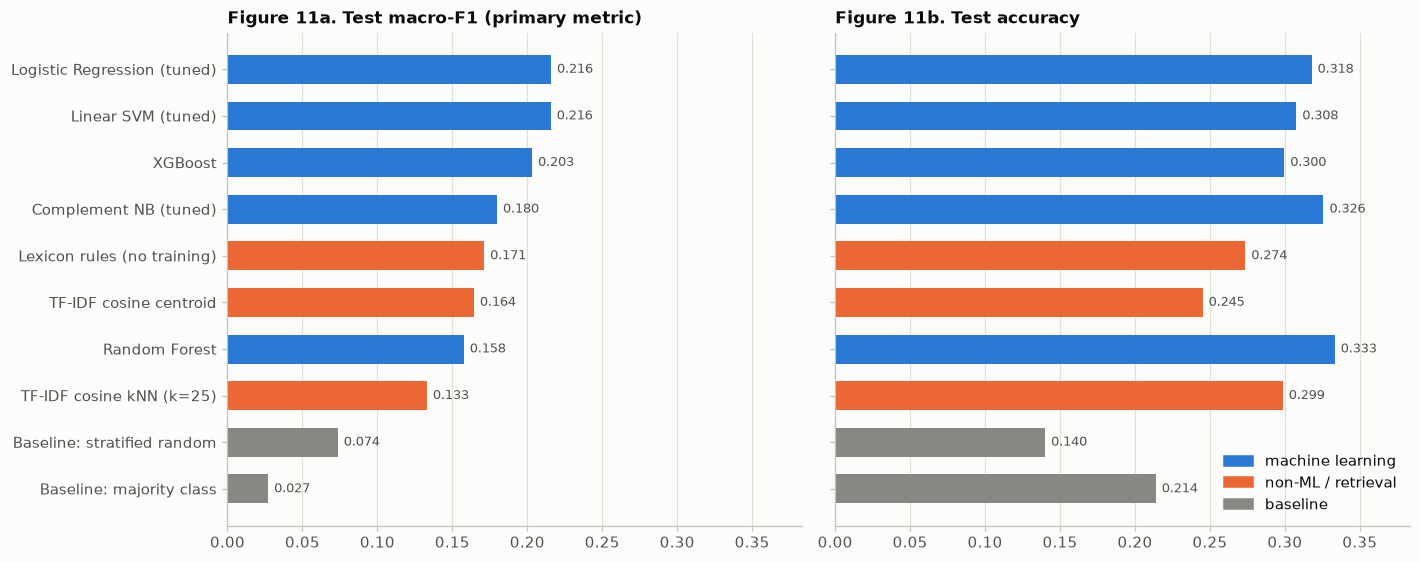

In [26]:
fam_color = {"ML": BLUE, "Non-ML": ORANGE, "Baseline": GRAY}
plot_df = res.sort_values("test_macro_f1")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, col, ttl in [(axes[0], "test_macro_f1", "Figure 11a. Test macro-F1 (primary metric)"), (axes[1], "test_acc", "Figure 11b. Test accuracy")]:
    ax.barh(plot_df["model"], plot_df[col], color=[fam_color[f] for f in plot_df["family"]], height=0.62)
    for i, v in enumerate(plot_df[col]):
        ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, max(plot_df["test_acc"].max(), plot_df["test_macro_f1"].max()) * 1.15)
    ax.set_title(ttl); grid(ax, "x")
axes[1].legend(handles=[Patch(color=fam_color[k], label=l) for k, l in [("ML", "machine learning"), ("Non-ML", "non-ML / retrieval"), ("Baseline", "baseline")]], loc="lower right")
plt.tight_layout(); plt.show()

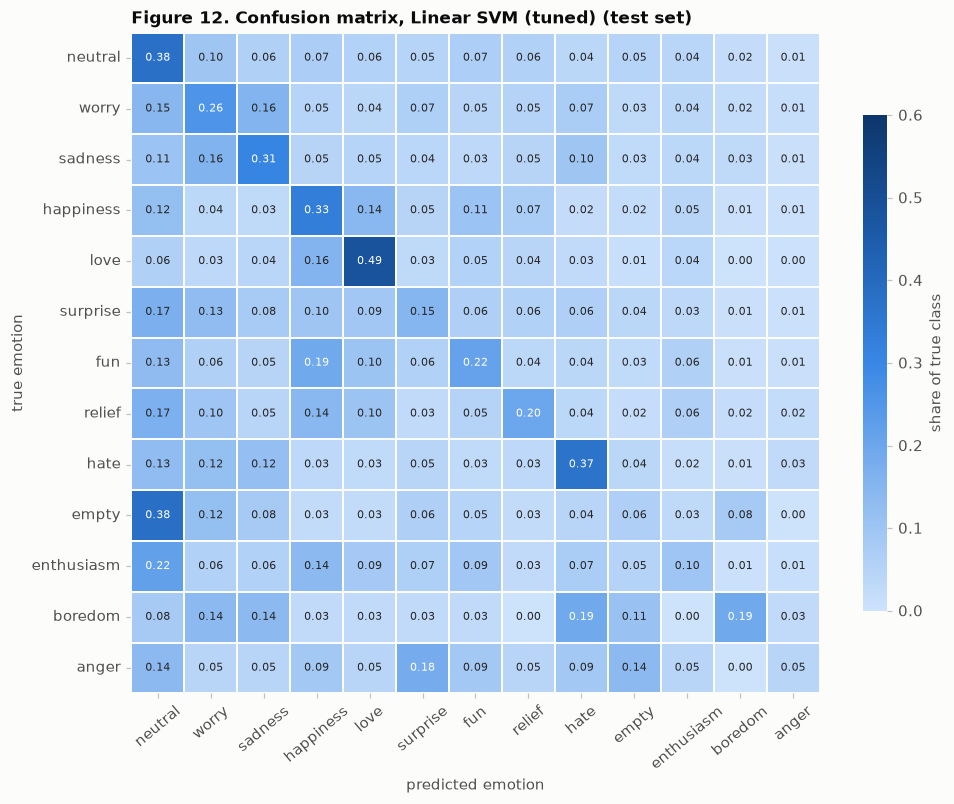

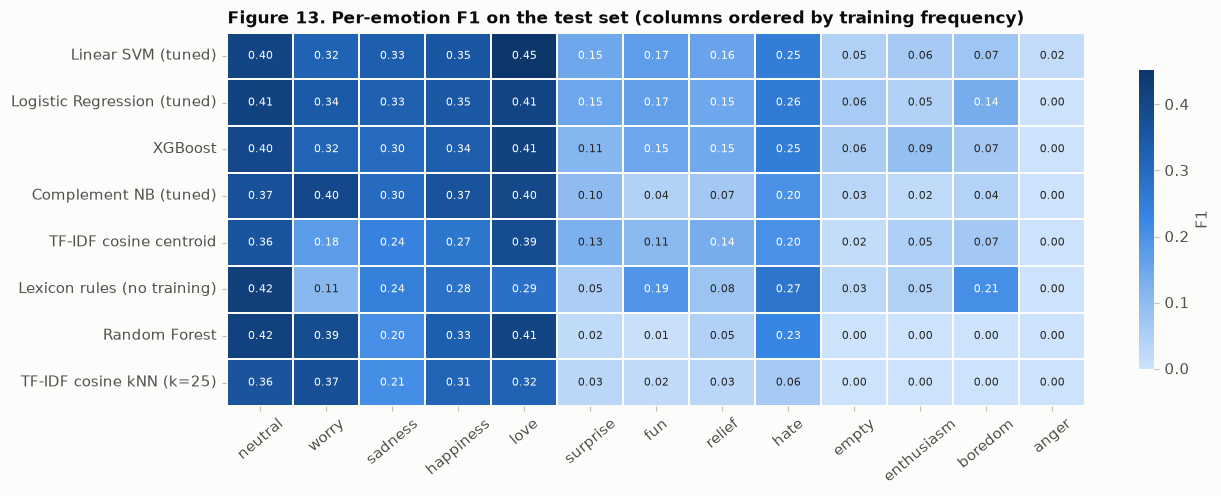

In [27]:
order_k = np.argsort(-np.bincount(y_train, minlength=K))
cm = confusion_matrix(y_test, RESULTS[BEST]["test_pred"], labels=order_k, normalize="true")
fig, ax = plt.subplots(figsize=(9.2, 7.4))
sns.heatmap(cm, cmap=SEQ, vmin=0, vmax=max(0.6, cm.max()), annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=1, linecolor=SURFACE,
            xticklabels=CLASSES[order_k], yticklabels=CLASSES[order_k], cbar_kws={"shrink": 0.75, "label": "share of true class"}, ax=ax)
ax.set_xlabel("predicted emotion"); ax.set_ylabel("true emotion")
ax.set_title(f"Figure 12. Confusion matrix, {BEST} (test set)")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

mods = list(contenders["model"])
f1_tab = pd.DataFrame({m: f1_score(y_test, RESULTS[m]["test_pred"], average=None, labels=np.arange(K), zero_division=0) for m in mods},
                      index=CLASSES).loc[CLASSES[order_k]].T
fig, ax = plt.subplots(figsize=(12, 4.6))
sns.heatmap(f1_tab, cmap=SEQ, vmin=0, annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=1, linecolor=SURFACE,
            cbar_kws={"shrink": 0.8, "label": "F1"}, ax=ax)
ax.set_title("Figure 13. Per-emotion F1 on the test set (columns ordered by training frequency)")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

Highest-weight words per emotion (Logistic Regression):


,top words
neutral,"looking for, got home, now it, to do, is like,..."
worry,"sad, not good, poor, worried, sick, sad that, ..."
sadness,"sad, no, cry, wish was, rip, sadly, oh no"
happiness,"can wait, thanks, nice to, fun, ! now, ever, lol"
love,"love, happy, loving, don want, with my, loved,..."
surprise,"wow, usertoken awesome, oh, and then, mom too,..."
fun,"fun, wait to, sing, lol, look, one for, tonight ?"
relief,"finally, it fun, done with, glad, urltoken hah..."
hate,"hate, want to, have to, shit, usertoken going,..."
empty,"im not, yes lol, work work, loves, bed soon, y..."


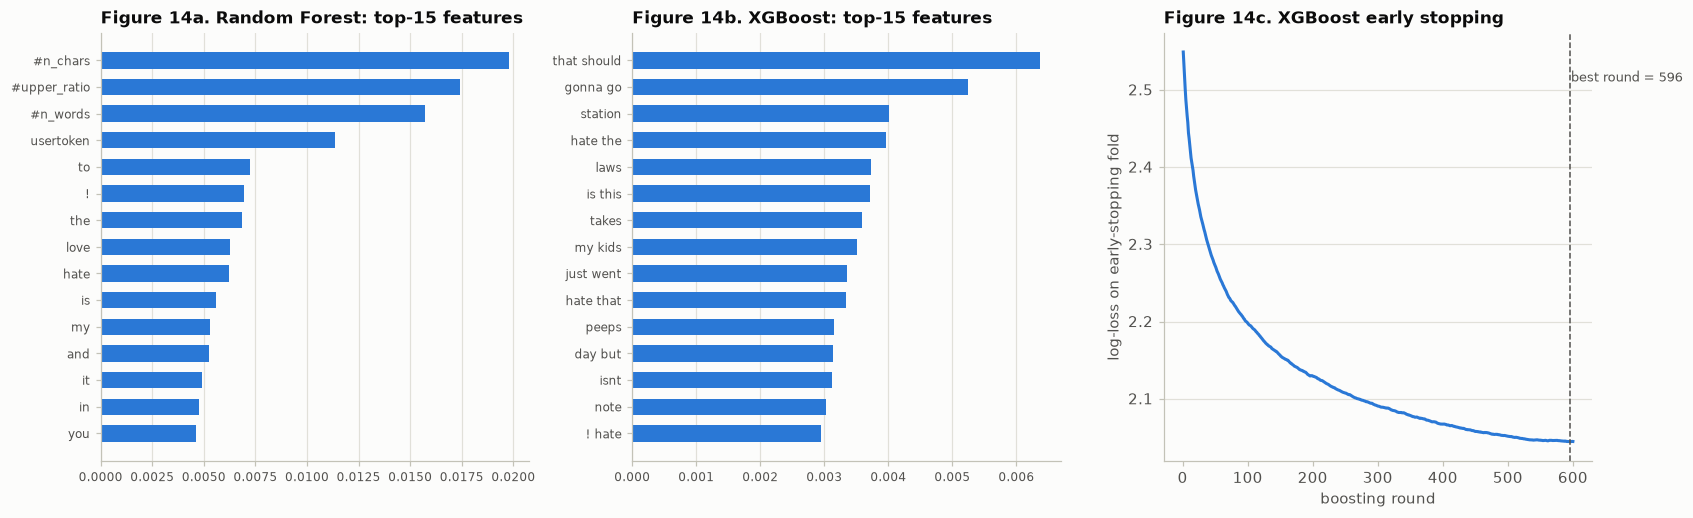

In [28]:
lr_best = RESULTS["Logistic Regression (tuned)"]["model"]
coef = lr_best.named_steps["clf"].coef_
fnames = lr_best.named_steps["f"].get_feature_names_out()
is_word = np.array([n.startswith("word__") for n in fnames])
words = np.array([n.replace("word__", "") for n in fnames])
top_terms = {CLASSES[k]: ", ".join(words[is_word][np.argsort(coef[k][is_word])[-7:][::-1]]) for k in range(K)}
print("Highest-weight words per emotion (Logistic Regression):")
display(pd.Series(top_terms, name="top words").loc[CLASSES[order_k]].to_frame())

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, mdl, ttl in [(axes[0], rf, "Figure 14a. Random Forest: top-15 features"), (axes[1], xgb_clf, "Figure 14b. XGBoost: top-15 features")]:
    imp = mdl.feature_importances_
    top = np.argsort(imp)[-15:]
    ax.barh(tree_names[top], imp[top], color=BLUE, height=0.62)
    ax.set_title(ttl); ax.tick_params(labelsize=8); grid(ax, "x")
ev = xgb_clf.evals_result()["validation_0"]["mlogloss"]
axes[2].plot(range(1, len(ev) + 1), ev, color=BLUE, linewidth=2)
axes[2].axvline(xgb_clf.best_iteration + 1, color=INK2, linestyle="--", linewidth=1)
axes[2].text(xgb_clf.best_iteration + 1 + 1, max(ev) * 0.985, f"best round = {xgb_clf.best_iteration + 1}", color=INK2, fontsize=8.5)
axes[2].set_xlabel("boosting round"); axes[2].set_ylabel("log-loss on early-stopping fold")
axes[2].set_title("Figure 14c. XGBoost early stopping"); grid(axes[2], "y")
plt.tight_layout(); plt.show()

In [29]:
pred_best = RESULTS[BEST]["test_pred"]
wrong = np.where(pred_best != y_test)[0]
sample = rng.choice(wrong, size=min(10, len(wrong)), replace=False)
pd.set_option("display.max_colwidth", 110)
display(pd.DataFrame({"tweet": X_test[sample], "true": CLASSES[y_test[sample]], "predicted": CLASSES[pred_best[sample]]}))
print(f"{BEST}: {len(wrong):,} of {len(y_test):,} test tweets misclassified ({len(wrong)/len(y_test):.1%}).")
print("\nPer-class report of the selected model (test set):")
print(classification_report(y_test, pred_best, labels=np.arange(K), target_names=CLASSES, digits=3, zero_division=0))

,tweet,true,predicted
0,@andrewschof hows u? lovely day here!,neutral,love
1,"@MandyyJirouxx MANDY!!! IT WON'T LET ME VOTE I WANT HER TO WIN BUT I CAN'T HELP, I AM GONNA JUMP OFF A B...",sadness,fun
2,i think that studying has really started taking its toll..,boredom,empty
3,"First impression of Silverlight: sadly, based on what I saw today, it's quite problematic",neutral,surprise
4,@Free2b_you Ah! Haha that's exciting. If I ever come to Australia we are definitely gonna have a movie nig...,worry,happiness
5,omgeee that hurt like helll. finally got it back in. can't close it put the ball back in,worry,relief
6,Just had mothers day lunch here http://twitpic.com/4wfeo,neutral,love
7,@shi819 my gaming thingy. Mine finally died after 5 years. RIP.,sadness,relief
8,@grungeheart_ - hey there. How was your day?,neutral,enthusiasm
9,some1 said if your not online your a no1...if you are online your a no1.. can't bloody win lol,worry,boredom


Linear SVM (tuned): 5,429 of 7,841 test tweets misclassified (69.2%).

Per-class report of the selected model (test set):
              precision    recall  f1-score   support

       anger      0.012     0.045     0.019        22
     boredom      0.046     0.194     0.074        36
       empty      0.038     0.064     0.047       157
  enthusiasm      0.046     0.100     0.063       150
         fun      0.144     0.215     0.172       353
   happiness      0.377     0.333     0.353      1019
        hate      0.192     0.369     0.253       263
        love      0.423     0.486     0.452       741
     neutral      0.434     0.379     0.405      1677
      relief      0.131     0.200     0.158       300
     sadness      0.362     0.307     0.332      1022
    surprise      0.147     0.151     0.149       431
       worry      0.434     0.259     0.324      1670

    accuracy                          0.308      7841
   macro avg      0.214     0.239     0.216      7841
weighted avg

### 5. Strengths and weaknesses of the algorithms

| Algorithm | Strengths | Weaknesses |
|---|---|---|
| Majority / random baseline | defines the floor every real model must beat | learns nothing; majority class gives zero recall on 12 emotions |
| Lexicon rules | needs no data, fully transparent, instant | no context or sarcasm, coverage limited by the hand-written word list, many tweets fall through to the default class |
| TF-IDF cosine centroid | tiny model, trains in a blink, interpretable class prototypes | assumes each emotion is one compact cluster, which is violated when classes overlap (Figures 6-8) |
| TF-IDF cosine k-NN | non-parametric, no training, can use near-duplicate evidence | slow at prediction time, dominated by the largest classes, distances are noisy in sparse high dimensions |
| Complement Naive Bayes | very fast, designed for imbalanced text, few hyper-parameters | conditional-independence assumption, poorly calibrated scores |
| Logistic Regression | strong text baseline, interpretable coefficients, probability outputs | linear boundaries only, needs regularisation tuning, slower than SVM on huge feature spaces |
| Linear SVM | usually the strongest classic model on sparse TF-IDF, fast | no native probabilities, sensitive to `C` and class weights |
| Random Forest | non-linear, robust to scale, gives feature importance | each tree sees few of the many sparse term features, large memory footprint, slow prediction |
| XGBoost | captures interactions (e.g. between descriptors and terms), early stopping controls over-fitting | many hyper-parameters, sparse text is not its natural habitat, longest training time here |

The next cell states which of these expectations the data actually confirmed.

In [30]:
b = res[res.model == BEST].iloc[0]
fam_best = res[res.family == "ML"].iloc[0]
non_ml_best = res[res.family == "Non-ML"].iloc[0]
fastest = res[res.family != "Baseline"].sort_values("fit_seconds").iloc[0]
print(f"Best overall (validation macro-F1): {b.model}: test macro-F1 {b.test_macro_f1:.3f}, accuracy {b.test_acc:.3f}")
print(f"Best ML model        : {fam_best.model} (test macro-F1 {fam_best.test_macro_f1:.3f})")
print(f"Best non-ML algorithm: {non_ml_best.model} (test macro-F1 {non_ml_best.test_macro_f1:.3f})")
print(f"Fastest to fit       : {fastest.model} ({fastest.fit_seconds:.2f}s)")
rf_f1, xgb_f1 = res.set_index("model").loc["Random Forest", "test_macro_f1"], res.set_index("model").loc["XGBoost", "test_macro_f1"]
lin_best = res[res.model.isin(["Linear SVM (tuned)", "Logistic Regression (tuned)"])].test_macro_f1.max()
print(f"Linear models vs tree ensembles (test macro-F1): {lin_best:.3f} vs {max(rf_f1, xgb_f1):.3f}")
rand_f1 = res.set_index("model").loc["Baseline: stratified random", "test_macro_f1"]
print(f"All non-baseline models beat the random baseline ({rand_f1:.3f}): {bool((res[res.family != 'Baseline'].test_macro_f1 > rand_f1).all())}")
gap = b.test_acc - b.test_macro_f1
print(f"\nH3: accuracy {b.test_acc:.3f} vs macro-F1 {b.test_macro_f1:.3f} (gap {gap:+.3f}); "
      f"best accuracy of any model = {res.test_acc.max():.3f}. "
      f"H3 {'is supported' if (gap > 0.02 and res.test_acc.max() < 0.6) else 'is NOT clearly supported'} by these numbers.")

Best overall (validation macro-F1): Linear SVM (tuned): test macro-F1 0.216, accuracy 0.308
Best ML model        : Linear SVM (tuned) (test macro-F1 0.216)
Best non-ML algorithm: TF-IDF cosine centroid (test macro-F1 0.164)
Fastest to fit       : Lexicon rules (no training) (0.00s)
Linear models vs tree ensembles (test macro-F1): 0.216 vs 0.203
All non-baseline models beat the random baseline (0.074): True

H3: accuracy 0.308 vs macro-F1 0.216 (gap +0.092); best accuracy of any model = 0.333. H3 is supported by these numbers.


### 6. Validation of the solution

A set of automatic checks guards against the typical ways such a pipeline silently goes wrong: leakage between splits, broken stratification, metric bugs, a model that is no better than chance, and a pipeline that "learns" from shuffled labels.

In [31]:
checks = []
def check(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))
    assert ok, f"validation check failed: {name} {detail}"

tr, va, te = (set(norm_all[i]) for i in (idx_train, idx_val, idx_test))
check("no normalised text shared between train / val / test", not (tr & va) and not (tr & te) and not (va & te),
      f"overlaps: {len(tr & va)}, {len(tr & te)}, {len(va & te)}")

check("cleaned data has unique texts and one label per text", df_clean.text_norm.is_unique)

dev = split_tbl.sub(split_tbl["all"], axis=0).abs().max().max()
check("class shares in every split within 1 percentage point of overall", dev < 0.01, f"max deviation {dev*100:.2f} pp")

p = RESULTS[BEST]["test_pred"]
cmx = confusion_matrix(y_test, p, labels=np.arange(K))
tp = np.diag(cmx).astype(float); fp = cmx.sum(0) - tp; fn = cmx.sum(1) - tp
den = 2 * tp + fp + fn
f1_manual = np.divide(2 * tp, den, out=np.zeros(K), where=den > 0).mean()
s = score_row(y_test, p)
check("accuracy recomputed from confusion matrix matches sklearn", np.isclose(tp.sum() / cmx.sum(), s["acc"]))
check("macro-F1 recomputed from confusion matrix matches sklearn", np.isclose(f1_manual, s["macro_f1"]), f"{f1_manual:.4f} vs {s['macro_f1']:.4f}")

check("every model returns one valid label per test tweet",
      all(len(r["test_pred"]) == len(y_test) and r["test_pred"].min() >= 0 and r["test_pred"].max() < K for r in RESULTS.values()))

rand = score_row(y_test, RESULTS["Baseline: stratified random"]["test_pred"])["macro_f1"]
worst = min(score_row(y_test, r["test_pred"])["macro_f1"] for n, r in RESULTS.items() if r["family"] == "ML")
check("every ML model beats random macro-F1", worst > rand, f"worst ML model {worst:.3f} vs random {rand:.3f}")

perm_pipe = Pipeline([("f", tfidf_word()), ("clf", LinearSVC(C=0.3, class_weight="balanced", random_state=SEED))])
y_perm = np.random.default_rng(SEED).permutation(y_train)
perm_pipe.fit(X_train, y_perm)
perm_f1 = score_row(y_val, perm_pipe.predict(X_val))["macro_f1"]
real_f1 = abl.loc["B  word 1-2-grams", "val_macro_f1"]
check("shuffled-label control collapses to near-chance macro-F1", perm_f1 < 0.5 * real_f1,
      f"shuffled {perm_f1:.3f} vs real {real_f1:.3f} (same features, same classifier)")

display(pd.DataFrame(checks))

,check,result,detail
0,no normalised text shared between train / val / test,PASS,"overlaps: 0, 0, 0"
1,cleaned data has unique texts and one label per text,PASS,
2,class shares in every split within 1 percentage point of overall,PASS,max deviation 0.01 pp
3,accuracy recomputed from confusion matrix matches sklearn,PASS,
4,macro-F1 recomputed from confusion matrix matches sklearn,PASS,0.2156 vs 0.2156
5,every model returns one valid label per test tweet,PASS,
6,every ML model beats random macro-F1,PASS,worst ML model 0.158 vs random 0.074
7,shuffled-label control collapses to near-chance macro-F1,PASS,"shuffled 0.073 vs real 0.186 (same features, same classifier)"


## Hypothesis Testing

Compare two ML algorithms. The following statistical hypotheses recommended:

- $H_0$: There is no statistically significant difference in the performance of two algorithms (for example,  Random Forest and XGBoost).
- $H_1$: There is a statistically significant difference in their performance.

### Method

Random Forest and XGBoost are compared on **identical data, features and class-weighting**, with macro-F1 as the primary metric (accuracy is reported as well). Three complementary procedures are used, because each has a different weakness:

| Procedure | What it tests | Caveat |
|---|---|---|
| **Exact McNemar test** on the test set | do the two classifiers err on *different* tweets at different rates (accuracy)? | based on one training run and one split; ignores training-set variability |
| **Paired bootstrap** of the test set | 95 % confidence interval and p-value for the macro-F1 difference | same single-split limitation, but works for macro-F1 |
| **k-fold CV + Nadeau–Bengio corrected paired t-test** (primary) | does the macro-F1 difference survive re-training on different data? | needs *k* re-fits per model (slow); the variance correction accounts for overlapping training sets |

Significance level $\alpha=0.05$. The decision about $H_0$ is taken from the cross-validated corrected *t*-test when it is run (it accounts for training variability); otherwise from the bootstrap. A non-significant result means "no detectable difference", not proof that the models are equivalent.

In [32]:

alpha = 0.05
pa, pb = RESULTS["Random Forest"]["test_pred"], RESULTS["XGBoost"]["test_pred"]
n_t = len(y_test)

ok_a, ok_b = pa == y_test, pb == y_test
n_both, n_rf_only, n_xgb_only, n_none = int((ok_a & ok_b).sum()), int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum()), int((~ok_a & ~ok_b).sum())
mc_p = stats.binomtest(n_rf_only, n_rf_only + n_xgb_only, 0.5).pvalue if (n_rf_only + n_xgb_only) > 0 else 1.0
print("Contingency table of correct predictions on the test set:")
display(pd.DataFrame([[n_both, n_rf_only], [n_xgb_only, n_none]], index=["RF correct", "RF wrong"],
                     columns=["XGBoost correct", "XGBoost wrong"]))
print(f"RF right & XGB wrong: {n_rf_only} | XGB right & RF wrong: {n_xgb_only}")
print(f"Exact McNemar test (accuracy): p = {mc_p:.4g}")
print(f"accuracy: RF {ok_a.mean():.4f} vs XGBoost {ok_b.mean():.4f}")

def fast_macro_f1(y, p, K):
    cmx = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cmx).astype(float); fp = cmx.sum(0) - tp; fn = cmx.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0).mean()

assert np.isclose(fast_macro_f1(y_test, pa, K), score_row(y_test, pa)["macro_f1"]), "fast macro-F1 disagrees with sklearn"
B = 2000
brng = np.random.default_rng(SEED)
boot = np.empty(B)
for i in range(B):
    ix = brng.integers(0, n_t, n_t)
    boot[i] = fast_macro_f1(y_test[ix], pa[ix], K) - fast_macro_f1(y_test[ix], pb[ix], K)
obs_diff = fast_macro_f1(y_test, pa, K) - fast_macro_f1(y_test, pb, K)
ci = np.percentile(boot, [2.5, 97.5])
boot_p = min(1.0, 2 * min((boot <= 0).mean(), (boot >= 0).mean()) + 1 / B)
print(f"\nPaired bootstrap ({B} resamples): macro-F1 RF - XGBoost = {obs_diff:+.4f}, 95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}], p ~ {boot_p:.4g}")


Contingency table of correct predictions on the test set:


,XGBoost correct,XGBoost wrong
RF correct,1508,1105
RF wrong,841,4387


RF right & XGB wrong: 1105 | XGB right & RF wrong: 841
Exact McNemar test (accuracy): p = 2.361e-09
accuracy: RF 0.3332 vs XGBoost 0.2996

Paired bootstrap (2000 resamples): macro-F1 RF - XGBoost = -0.0455, 95% CI [-0.0567, -0.0346], p ~ 0.0005


In [33]:
cv_df = None
if RUN_CV_TEST:
    rf_params = rf.get_params()
    xgb_params = {k: v for k, v in XGB_PARAMS.items() if k != "early_stopping_rounds"}
    xgb_params["n_estimators"] = int(xgb_clf.best_iteration) + 1
    skf = StratifiedKFold(n_splits=CV_TEST_FOLDS, shuffle=True, random_state=SEED)
    rows = []
    t0 = time.time()
    for k, (tr_i, te_i) in enumerate(skf.split(X_trval, y_trval), start=1):
        feats = make_tree_features().fit(X_trval[tr_i])
        Xa, Xb = feats.transform(X_trval[tr_i]), feats.transform(X_trval[te_i])
        m_rf = RandomForestClassifier(**rf_params).fit(Xa, y_trval[tr_i])
        m_xgb = xgb.XGBClassifier(**xgb_params).fit(Xa, y_trval[tr_i], sample_weight=compute_sample_weight("balanced", y_trval[tr_i]))
        s_rf, s_xgb = score_row(y_trval[te_i], m_rf.predict(Xb)), score_row(y_trval[te_i], m_xgb.predict(Xb))
        rows.append(dict(fold=k, rf_macro_f1=s_rf["macro_f1"], xgb_macro_f1=s_xgb["macro_f1"], rf_acc=s_rf["acc"], xgb_acc=s_xgb["acc"]))
        print(f"fold {k}/{CV_TEST_FOLDS} done ({time.time() - t0:.0f}s)")
    cv_df = pd.DataFrame(rows).set_index("fold")
    display(cv_df.round(4))

def corrected_paired_t(d, k):
    d = np.asarray(d, dtype=float); n = len(d); var = d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / n + 1 / (k - 1)) * var)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

cv_summary = {}
if cv_df is not None:
    for metric, a_col, b_col in [("macro-F1", "rf_macro_f1", "xgb_macro_f1"), ("accuracy", "rf_acc", "xgb_acc")]:
        d = cv_df[a_col] - cv_df[b_col]
        t_c, p_c = corrected_paired_t(d, CV_TEST_FOLDS)
        t_u, p_u = stats.ttest_rel(cv_df[a_col], cv_df[b_col])
        try:
            p_w = stats.wilcoxon(d).pvalue
        except ValueError:
            p_w = np.nan
        dz = d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan
        cv_summary[metric] = dict(mean_diff=d.mean(), t_corrected=t_c, p_corrected=p_c, p_uncorrected=p_u, p_wilcoxon=p_w, cohen_dz=dz)
    print("\nRF - XGBoost, fold-wise differences:")
    display(pd.DataFrame(cv_summary).T.round(4))
else:
    print("RUN_CV_TEST is False: the cross-validated comparison was skipped.")

fold 1/5 done (280s)
fold 2/5 done (534s)
fold 3/5 done (784s)
fold 4/5 done (1035s)
fold 5/5 done (1287s)


,rf_macro_f1,xgb_macro_f1,rf_acc,xgb_acc
fold,,,,
1,0.1551,0.1968,0.3297,0.2994
2,0.1560,0.1986,0.3262,0.2991
3,0.1552,0.1947,0.3296,0.2907
4,0.1590,0.1971,0.3256,0.2983
5,0.1538,0.1875,0.3265,0.2948



RF - XGBoost, fold-wise differences:


,mean_diff,t_corrected,p_corrected,p_uncorrected,p_wilcoxon,cohen_dz
macro-F1,-0.0391,-16.4522,0.0001,0.0000,0.0625,-11.0365
accuracy,0.0311,9.6220,0.0007,0.0001,0.0625,6.4546


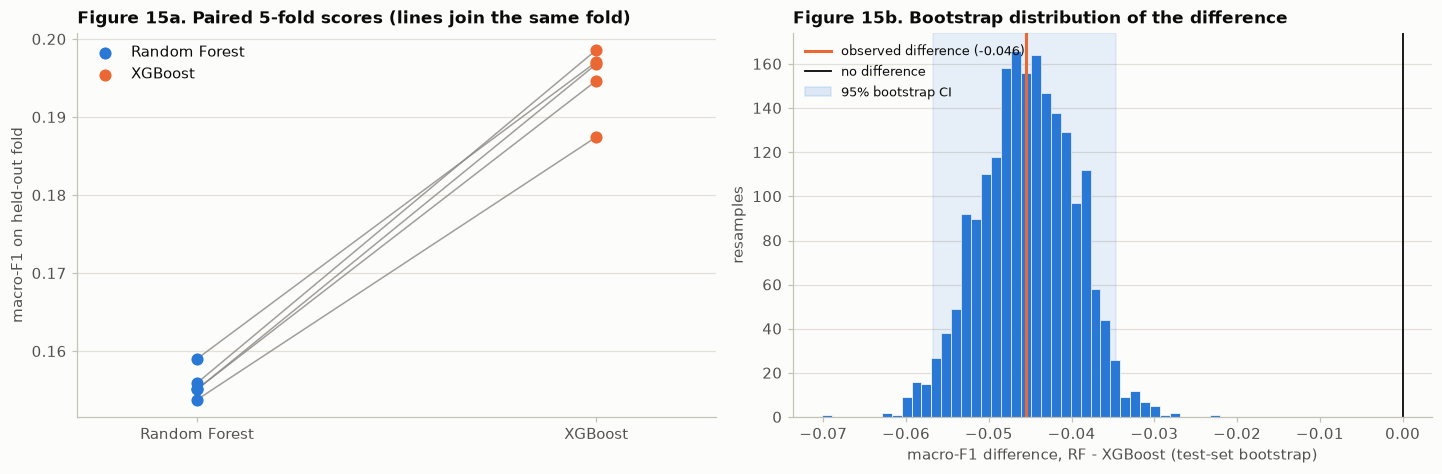

In [34]:
ncols = 2 if cv_df is not None else 1
fig, axes = plt.subplots(1, ncols, figsize=(6.6 * ncols, 4.4))
axes = np.atleast_1d(axes)
ax = axes[0]
if cv_df is not None:
    for _, r in cv_df.iterrows():
        ax.plot([0, 1], [r.rf_macro_f1, r.xgb_macro_f1], color=GRAY, linewidth=1, alpha=0.8, zorder=1)
    ax.scatter(np.zeros(len(cv_df)), cv_df.rf_macro_f1, color=BLUE, s=48, zorder=2, label="Random Forest")
    ax.scatter(np.ones(len(cv_df)), cv_df.xgb_macro_f1, color=ORANGE, s=48, zorder=2, label="XGBoost")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Random Forest", "XGBoost"]); ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel("macro-F1 on held-out fold")
    ax.set_title(f"Figure 15a. Paired {CV_TEST_FOLDS}-fold scores (lines join the same fold)")
    ax.legend(loc="best"); grid(ax, "y")
    ax = axes[1]
ax.hist(boot, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(0, color=INK, linewidth=1.2)
ax.axvline(obs_diff, color=ORANGE, linewidth=2)
ax.axvspan(ci[0], ci[1], color=BLUE, alpha=0.10)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=ORANGE, lw=2, label=f"observed difference ({obs_diff:+.3f})"),
                   Line2D([0], [0], color=INK, lw=1.2, label="no difference"),
                   Patch(color=BLUE, alpha=0.15, label="95% bootstrap CI")], loc="upper left", fontsize=8.5)
ax.set_xlabel("macro-F1 difference, RF - XGBoost (test-set bootstrap)")
ax.set_ylabel("resamples")
ax.set_title("Figure 15b. Bootstrap distribution of the difference")
grid(ax, "y")
plt.tight_layout(); plt.show()

In [35]:
print("H0: no statistically significant difference between Random Forest and XGBoost (alpha = 0.05)\n")
summary = [("Exact McNemar (accuracy, test set)", mc_p), ("Paired bootstrap (macro-F1, test set)", boot_p)]
if cv_df is not None:
    summary.append((f"{CV_TEST_FOLDS}-fold corrected paired t (macro-F1)  <- primary", cv_summary["macro-F1"]["p_corrected"]))
    summary.append((f"{CV_TEST_FOLDS}-fold corrected paired t (accuracy)", cv_summary["accuracy"]["p_corrected"]))
for name, p in summary:
    print(f"{name:55s} p = {p:8.4g}   -> {'reject H0' if p < alpha else 'fail to reject H0'}")

primary_p = cv_summary["macro-F1"]["p_corrected"] if cv_df is not None else boot_p
better = "Random Forest" if obs_diff > 0 else "XGBoost"
print("\nConclusion:")
if primary_p < alpha:
    print(f"  H0 is rejected: the performance of Random Forest and XGBoost differs significantly (p = {primary_p:.3g}); "
          f"{better} is ahead by {abs(obs_diff):.3f} macro-F1 on the test set.")
else:
    print(f"  H0 cannot be rejected (p = {primary_p:.3g}): there is no statistically detectable difference between "
          f"Random Forest and XGBoost on this data (test-set macro-F1 gap {abs(obs_diff):.3f} in favour of {better}). "
          "That is absence of evidence of a difference, not evidence of equivalence.")
agree = all((p < alpha) == (primary_p < alpha) for _, p in summary)
print(f"  The {len(summary)} procedures {'agree' if agree else 'do NOT all agree'} on the decision.")
FINDINGS["HT"] = dict(primary_p=primary_p, better=better, obs_diff=obs_diff)

H0: no statistically significant difference between Random Forest and XGBoost (alpha = 0.05)

Exact McNemar (accuracy, test set)                      p = 2.361e-09   -> reject H0
Paired bootstrap (macro-F1, test set)                   p =   0.0005   -> reject H0
5-fold corrected paired t (macro-F1)  <- primary        p = 7.992e-05   -> reject H0
5-fold corrected paired t (accuracy)                    p = 0.0006523   -> reject H0

Conclusion:
  H0 is rejected: the performance of Random Forest and XGBoost differs significantly (p = 7.99e-05); XGBoost is ahead by 0.046 macro-F1 on the test set.
  The 4 procedures agree on the decision.


## Conclusions

In [36]:
b = res[res.model == BEST].iloc[0]
print("SUMMARY (all numbers come from the cells above)\n")
print(f"EDA   : {len(df_clean):,} unique tweets after cleaning ({len(df_clean)/n_raw:.1%} of the raw file), 13 emotions, imbalance {cls.max()/cls.min():.0f}:1, "
      f"median {meta_c.n_words.median():.0f} words per tweet.")
print(f"        RQ1 length differs across emotions: {p_str(FINDINGS['RQ1']['p'])}, effect size epsilon^2 = {FINDINGS['RQ1']['eps2']:.4f}.")
print(f"        RQ2 '!' in positive vs negative emotions: {FINDINGS['RQ2']['share_pos']:.1%} vs {FINDINGS['RQ2']['share_neg']:.1%}, {p_str(FINDINGS['RQ2']['p'])}.")
print(f"ML    : best model {b.model}: test macro-F1 {b.test_macro_f1:.3f}, accuracy {b.test_acc:.3f}, balanced accuracy {b.test_bal_acc:.3f}.")
print(f"        best non-ML algorithm: {non_ml_best.model} (macro-F1 {non_ml_best.test_macro_f1:.3f}).")
print(f"HYP   : RF vs XGBoost, primary {p_str(FINDINGS['HT']['primary_p'])} -> "
      f"{'significant difference' if FINDINGS['HT']['primary_p'] < alpha else 'no significant difference'}.")
print(f"CHECKS: {sum(c['result'] == 'PASS' for c in checks)}/{len(checks)} validation checks passed.")

SUMMARY (all numbers come from the cells above)

EDA   : 39,202 unique tweets after cleaning (98.0% of the raw file), 13 emotions, imbalance 76:1, median 12 words per tweet.
        RQ1 length differs across emotions: p = 8.99e-197, effect size epsilon^2 = 0.0244.
        RQ2 '!' in positive vs negative emotions: 40.8% vs 25.0%, p = 1.8e-181.
ML    : best model Linear SVM (tuned): test macro-F1 0.216, accuracy 0.308, balanced accuracy 0.239.
        best non-ML algorithm: TF-IDF cosine centroid (macro-F1 0.164).
HYP   : RF vs XGBoost, primary p = 7.99e-05 -> significant difference.
CHECKS: 8/8 validation checks passed.
